# Dividing Lines
## What separates Luminal A from Luminal B breast tumours?

*Computing for Bioinformatics, group project.* A gene-expression study of 59 breast tumours from the public dataset **GEO GSE45827** (Institut Curie, France).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DiorWachira/dividing-lines/blob/main/dividing_lines.ipynb) · [Companion site](https://diorwachira.github.io/dividing-lines/) · [Repository](https://github.com/DiorWachira/dividing-lines)

The title has two meanings. **Cell division** turns out to be most of the biological answer, and a **dividing line** is exactly what the split between these two subtypes is: a line drawn through one continuous spread of tumours.

**How to read this notebook.** It runs top to bottom with no setup: press *Runtime → Run all* in Colab, and it finishes in a few minutes on a normal CPU. We wrote it for readers who have never studied biology. Every stage opens with three short parts:

* **What we're doing**: the step in plain words.
* **Why it matters**: the question the step answers, and what would go wrong if we skipped it.
* **What to look for below**: what a good result and a bad result look like *before* you see the output.

Every stage then closes with **What we found**, including anything that looked wrong.

| Stage | Contents |
|---|---|
| 1 | Question, objectives, hypothesis, and the honesty problem |
| 2 | Downloading and describing the data |
| 3 | Preprocessing and quality control |
| 4 | Exploring the data (four plots, including the MKI67 sanity check) |
| 5 | Differential expression: which genes differ? |
| 6 | Biological interpretation: what do those genes do, and how much of it is cell division? |
| 7 | Machine learning, with nested cross-validation and a ladder of baselines |
| 8 | Conclusions and limitations |

---
# Stage 1 · Question and objectives

**Research question.** *Which gene-expression differences distinguish Luminal A and Luminal B breast tumours, and how well can those differences classify the two groups?*

**Objectives**
1. Compare gene expression between Luminal A and Luminal B tumour samples.
2. Identify genes with statistically significant differences, correcting for multiple comparisons.
3. Interpret the strongest differences using gene-function or pathway information.
4. Compare a simple classifier against proper baselines to see whether the expression data can distinguish the two groups.

**Hypothesis.** The two subtypes differ mainly in *how fast the tumour cells divide*. So the genes that separate them will be dominated by cell-division genes, and a classifier will perform well. However, much of that performance will come from a small set of proliferation genes rather than from broad biological difference.

### Background in plain words
Breast cancer is not one disease. Doctors sort tumours into **subtypes**, families that behave alike and get similar treatment. Most breast tumours are *luminal*: their cells resemble the cells lining the milk ducts (the duct's hollow centre is called the *lumen*), and they grow in response to the hormone oestrogen. Luminal tumours are split in two. **Luminal A** grows slowly and usually does well on hormone therapy alone. **Luminal B** grows faster, and doctors are more likely to recommend **chemotherapy** as well. Getting the split right therefore changes what treatment a patient is offered.

### The honesty problem
Luminal A and Luminal B are not independent clinical facts. They were originally **defined from gene expression**: Luminal B is the one with higher activity of proliferation (cell-division) genes. So the question "can gene expression tell them apart?" has a guaranteed yes. A naive project would rediscover its own labels and report 95% accuracy.

We are not pretending otherwise. We state it openly and then **measure** it:
* How much of the separation comes from proliferation genes alone?
* Does anything survive when those genes are removed?

That turns a circular exercise into a real test, and either outcome is worth reporting.

### Declared before looking at any results
So that we cannot choose them after seeing what works, we fix these now:
* **Proliferation gene set:** the 21 PAM50 proliferation genes: *ANLN, BIRC5, CCNB1, CCNE1, CDC20, CDC6, NUF2 (CDCA1), CENPF, CEP55, EXO1, KIF2C, NDC80 (KNTC2), MELK, MKI67, MYBL2, ORC6, PTTG1, RRM2, TYMS, UBE2C, UBE2T*. (PAM50 is a published 50-gene test used to assign breast-cancer subtypes. These 21 are its cell-division genes.)
* **Wider cell-cycle set:** every probe whose gene is directly annotated in the platform file with the Gene Ontology terms *cell cycle* (GO:0007049) or *cell division* (GO:0051301).
* **Significance:** Benjamini–Hochberg false discovery rate (FDR) below 5%.
* **Strictest mask for Stage 7:** remove the PAM50 set, the GO cell-cycle set, *and* any probe whose correlation with the proliferation score is |r| ≥ 0.4, recomputed inside every training fold.

### Glossary (one line each, everyday language)
| Term | Meaning |
|---|---|
| **Gene** | A stretch of DNA that holds the recipe for one protein (one working part of a cell). |
| **Gene expression** | How strongly a gene is switched on right now, measured by how much of its message (RNA) the cell is making. |
| **Microarray** | A glass chip that works like ~54,000 tiny light meters, one per probe. A spot glows brighter the more of that gene's message is in the sample. |
| **Probe** | One spot on the chip, designed to catch the message of one gene. Some genes have several probes. |
| **Tumour subtype** | A family of tumours that behave alike and get similar treatment. |
| **Luminal A** | Hormone-sensitive breast cancer that grows slowly. It usually does well on hormone therapy alone. |
| **Luminal B** | Also hormone-sensitive, but faster-growing. Doctors are more likely to add chemotherapy. |
| **Proliferation** | How fast cells are dividing to make more cells. |
| **Differential expression** | A gene that is reliably more switched on in one group than the other. |
| **p-value** | If there were truly no difference, how often would chance alone produce a gap this big? Small means "rarely". |
| **Multiple-testing correction** | Adjusting p-values because running thousands of tests guarantees some lucky-looking results. |
| **False discovery rate (FDR)** | Among the genes we call significant, the share we expect to be false alarms. FDR 5% means about 1 in 20. |
| **Cross-validation** | Hiding some samples, training on the rest, testing on the hidden ones, then rotating so that every sample is tested once. |
| **Data leakage** | When information from the test samples sneaks into training, so the score looks better than it really is. |
| **Baseline** | A deliberately simple model to compare against. If the fancy model can't beat it, the fancy model hasn't learned much. |

### Setup
This cell loads the libraries, fixes random seeds so the results reproduce exactly, and sets one consistent colour scheme for every figure. **Luminal A is indigo** and **Luminal B is rose**, like the two classic tissue stains hematoxylin and eosin. **Brown is used only for proliferation** genes, like the brown Ki-67 stain pathologists use to spot dividing cells. We checked these colours for colour-blind readers.

In [1]:
# Install the one package Colab does not ship with (used only for an optional online cross-check).
import importlib.util, subprocess, sys
if importlib.util.find_spec("gseapy") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gseapy"], check=False)

import gzip, io, json, os, random, re, time, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

SEED = 45827                      # the accession number, so it is easy to remember
random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

DATA_DIR = Path("data");    DATA_DIR.mkdir(exist_ok=True)     # downloads (not committed)
FIG_DIR = Path("figures");  FIG_DIR.mkdir(exist_ok=True)      # every figure is saved here too
T0 = time.time()

# One palette for the whole project (validated for colour-blind safety).
LUM_A, LUM_B, PROLIF, INK, MUTED = "#4549A6", "#D04A86", "#7E4310", "#1F1C3D", "#8A86A0"
PAL = {"Luminal A": LUM_A, "Luminal B": LUM_B}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9A93A8", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "xtick.color": "#4A4766", "ytick.color": "#4A4766",
    "text.color": INK, "font.size": 10, "legend.frameon": False,
})

def save(fig, name):
    # Save a figure to figures/ and show it.
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

print("Libraries loaded. numpy", np.__version__, "| pandas", pd.__version__, "| seed", SEED)

Libraries loaded. numpy 2.5.5 | pandas 3.1.1 | seed 45827


---
# Stage 2 · Data acquisition

**What we're doing.** We download the dataset straight from the public NCBI archive (GEO), unpack it, and list everything it contains: the descriptions of the study, of each sample, and the measurements.

**Why it matters.** Everything later rests on this step. If we misread which tumour is which subtype, every result is wrong but would still *look* convincing. That is why we check the counts with a hard assertion instead of trusting our parsing.

**What to look for below.** A good result: the download succeeds, the file contains about 155 samples, and the subtype field gives **exactly 29 Luminal A and 30 Luminal B**. A bad result: any other count. The code then stops with an error instead of carrying on quietly.

In [2]:
# The "series matrix" is one gzipped text file holding the metadata and the expression table.
MATRIX_URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE45nnn/GSE45827/matrix/GSE45827_series_matrix.txt.gz"
matrix_path = DATA_DIR / "GSE45827_series_matrix.txt.gz"

def download(url, path):
    # Download once; later runs reuse the local copy.
    if path.exists() and path.stat().st_size > 0:
        print(f"Using cached {path.name} ({path.stat().st_size/1e6:.1f} MB)")
        return "cache"
    req = urllib.request.Request(url, headers={"User-Agent": "dividing-lines-coursework/1.0"})
    with urllib.request.urlopen(req, timeout=120) as r, open(path, "wb") as f:
        f.write(r.read())
    print(f"Downloaded {path.name} ({path.stat().st_size/1e6:.1f} MB) from {url}")
    return "ftp"

try:
    route = download(MATRIX_URL, matrix_path)
except Exception as err:   # fallback route described in the brief: GEOparse
    print("Direct download failed:", err, "→ trying GEOparse")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "GEOparse"], check=True)
    import GEOparse
    GEOparse.get_GEO(geo="GSE45827", destdir=str(DATA_DIR), how="brief")
    route = "GEOparse"
print("Route that worked:", route if route != "cache" else "cached copy of the direct NCBI FTP download")

Using cached GSE45827_series_matrix.txt.gz (15.7 MB)
Route that worked: cached copy of the direct NCBI FTP download


In [3]:
# Parse: lines starting with "!" are metadata; the table sits between the two markers.
with gzip.open(matrix_path, "rt", encoding="utf-8") as fh:
    lines = fh.read().splitlines()

start = lines.index("!series_matrix_table_begin")
end = lines.index("!series_matrix_table_end")

series_meta, sample_rows = {}, []
for line in lines[:start]:
    key, *vals = line.split("\t")
    vals = [v.strip('"') for v in vals]
    if key.startswith("!Series_"):
        series_meta.setdefault(key[len("!Series_"):], []).extend(vals)
    elif key.startswith("!Sample_"):
        sample_rows.append((key[len("!Sample_"):], vals))

# Some sample fields repeat (e.g. four 'characteristics' lines), so number the repeats.
seen, sample_meta = {}, {}
for key, vals in sample_rows:
    seen[key] = seen.get(key, 0) + 1
    name = key if seen[key] == 1 else f"{key}_{seen[key]}"
    sample_meta[name] = vals
sample_meta = pd.DataFrame(sample_meta)
sample_meta.index = sample_meta["geo_accession"]

expr_all = pd.read_csv(io.StringIO("\n".join(lines[start + 1:end])), sep="\t", index_col=0)
expr_all.columns = expr_all.columns.str.strip('"')
expr_all.index = expr_all.index.str.strip('"')
print(f"Metadata: {len(series_meta)} series-level fields, {sample_meta.shape[1]} per-sample fields")
print(f"Expression table: {expr_all.shape[0]:,} probes (rows) × {expr_all.shape[1]} samples (columns)")

Metadata: 27 series-level fields, 36 per-sample fields
Expression table: 29,873 probes (rows) × 155 samples (columns)


### Every variable, described
**Series-level fields** describe the whole study. We print them all. Contact phone, fax and email lines are summarised rather than printed, because they identify a person and are not needed for the analysis.

In [4]:
PRIVATE = {"contact_email", "contact_phone", "contact_fax"}
for key, vals in series_meta.items():
    if key in PRIVATE:
        print(f"{key:28s} [withheld: personal contact detail]")
        continue
    text = " | ".join(vals)
    if key == "sample_id":
        text = f"{len(text.split())} sample accessions, e.g. {' '.join(text.split()[:3])} …"
    print(f"{key:28s} {text[:400]}{'…' if len(text) > 400 else ''}")

title                        Expression data from Breast cancer subtypes
geo_accession                GSE45827
status                       Public on Mar 24 2016
submission_date              Apr 05 2013
last_update_date             Mar 25 2019
pubmed_id                    27006338
summary                      Expression data from Breast cancer subtypes
overall_design               In a cohort study of primary invasive breast cancer (41 TN, 30 HER2, 29 Luminal A and 30 Luminal B) as well as 11 normal tissues samples and 14 cell lines , we obtained a tumor specimen at surgery before any patient treatment. Total RNA was extracted from all samples and the whole transcriptome was quantified with Affymetrix U133 Plus 2.0 Chips.
type                         Expression profiling by array
contributor                  Tina,,Gruosso | Yann,,Kieffer | Thierry,,Dubois | Fatima,,Mechta-Grigoriou
sample_id                    155 sample accessions, e.g. GSM1116084 GSM1116085 GSM1116086 …
contact_name 

**Per-sample fields** describe each of the 155 samples. For each one we show how many distinct values it takes and an example. Fields with a single value are the same for every sample (for example the organism).

In [5]:
rows = []
for col in sample_meta.columns:
    vals = sample_meta[col]
    example = vals.iloc[0] if not col.startswith("contact_") or col in ("contact_institute", "contact_country", "contact_city") else "[withheld]"
    rows.append({"field": col, "distinct values": vals.nunique(), "example": str(example)[:110]})
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(rows))

,field,distinct values,example
0,title,155,Basal Sample1 rep1
1,geo_accession,155,GSM1116084
2,status,1,Public on Mar 24 2016
3,submission_date,1,Apr 05 2013
4,last_update_date,1,Mar 24 2016
5,type,1,RNA
6,channel_count,1,1
7,source_name_ch1,6,Human Basal Tumor Sample
8,organism_ch1,1,Homo sapiens
9,characteristics_ch1,16,diagnosis: Breast cancer


In [6]:
# The four 'characteristics' lines hold the useful per-sample variables.
for col in [c for c in sample_meta.columns if c.startswith("characteristics_ch1")]:
    print(col, "→", dict(sample_meta[col].value_counts()))

characteristics_ch1 → {'diagnosis: Breast cancer': np.int64(130), 'diagnosis: None (normal)': np.int64(11), 'cell line: BT20': np.int64(1), 'cell line: HCC70': np.int64(1), 'cell line: HCC1143': np.int64(1), 'cell line: HCC1187': np.int64(1), 'cell line: HCC1937': np.int64(1), 'cell line: MDA-MB-468': np.int64(1), 'cell line: HCC38': np.int64(1), 'cell line: MDA-MB-231': np.int64(1), 'cell line: MDA-MB-436': np.int64(1), 'cell line: MDA-MB-157': np.int64(1), 'cell line: BT-549': np.int64(1), 'cell line: Hs 578T': np.int64(1), 'cell line: MCF-12A': np.int64(1), 'cell line: 184B5': np.int64(1)}
characteristics_ch1_2 → {'tumor subtype: Basal': np.int64(41), 'tumor subtype: Her2': np.int64(30), 'tumor subtype: Luminal B': np.int64(30), 'tumor subtype: Luminal A': np.int64(29), 'cell origin: Breast carcinoma': np.int64(12), 'tumor subtype: N/A': np.int64(11), 'cell origin: Breast mammary gland': np.int64(2)}
characteristics_ch1_3 → {'batch: 9': np.int64(40), 'batch: 8': np.int64(22), 'batch

**The submitters' data-processing statement, verbatim.** This processing was done by the Institut Curie team before upload, not by us. The values we analyse are **processed microarray intensities, not raw sequencing counts**.

In [7]:
processing = sample_meta["data_processing"].unique()
assert len(processing) == 1, "Samples have different processing statements"
PROCESSING = processing[0]
print(PROCESSING)

The data were first normalized by using GC-RMA (R version 2.14.1). A linear mixed model using Restricted Maximum Likelihood (REML using name package) was then applied. The model included the different experimental batches and the sample type as fixed effects, and treated technical variation as random effects. No interaction terms were included. This model was used to derive significance for differential expression between different tumor types and for correction of batch and hybridization effects. For further analysis, technical replicates were averaged. We choose to discard probe-sets with noise-level signal from the analysis: specifically, we considered as not expressed and therefore discarded, all the probe-sets with a log2 intensity of less than 4 in 95% or more of tissue samples.


### Assigning the subtype labels, with a hard check
The subtype sits in the characteristics field written as `tumor subtype: Luminal A`. We parse it and **assert** the counts the study reports. If they differ, the notebook stops here.

In [8]:
def field(col, prefix):
    # Strip the 'name: ' prefix from a characteristics value.
    return sample_meta[col].str.replace(rf"^{prefix}:\s*", "", regex=True)

sample_meta["subtype"] = field("characteristics_ch1_2", "tumor subtype")
sample_meta["batch"] = field("characteristics_ch1_3", "batch")
sample_meta["hybridisation"] = field("characteristics_ch1_4", "hybridation")
print(sample_meta["subtype"].value_counts().to_string())

n_a = (sample_meta["subtype"] == "Luminal A").sum()
n_b = (sample_meta["subtype"] == "Luminal B").sum()
assert (n_a, n_b) == (29, 30), f"STOP: expected 29 Luminal A and 30 Luminal B, got {n_a} and {n_b}"
print(f"\n✔ Subtype check passed: {n_a} Luminal A and {n_b} Luminal B")

subtype
Basal                                41
Her2                                 30
Luminal B                            30
Luminal A                            29
cell origin: Breast carcinoma        12
N/A                                  11
cell origin: Breast mammary gland     2

✔ Subtype check passed: 29 Luminal A and 30 Luminal B


### Source, accession, platform, licence
* **Source:** NCBI Gene Expression Omnibus (GEO), series **GSE45827**, *"Expression data from Breast cancer subtypes"*, submitted by Institut Curie (Paris, France) in April 2013. The linked publication is Gruosso *et al.*, *EMBO Molecular Medicine* 2016 (PMID 27006338).
* **Platform:** **GPL570**, the Affymetrix Human Genome U133 Plus 2.0 microarray. The chip has 54,675 probes.
* **Collection:** tumour tissue taken at surgery, before any treatment. The data are de-identified.
* **Licence / terms:** NCBI places no restrictions on the use of GEO data, but notes that submitters may claim patent, copyright or other rights. We cite the submitters, use the data for non-commercial coursework, and do not redistribute it. The notebook downloads it fresh from NCBI.
* **Not mixed with GSE65194.** GSE65194 is the *same* Institut Curie cohort reprocessed with a different probe definition. We use **GSE45827 only** and never merge the two, because merging would double-count the same patients.

### What we found (Stage 2)
* The direct NCBI download worked, so we did not need the GEOparse fallback. The file holds **155 samples**: 41 basal (triple-negative), 30 HER2, 29 Luminal A, 30 Luminal B, 11 normal tissue and 14 cell lines, exactly as the study describes.
* The subtype field parsed cleanly to **29 Luminal A and 30 Luminal B**, and the assertion passed.
* **Something to note:** the expression table has **29,873 probes, not the 54,675** on the chip. The processing statement explains why. The submitters *already removed* probes that were near the noise floor ("log2 intensity of less than 4 in 95% or more of tissue samples"). This is their filtering, not ours.
* **A second thing to note:** the submitters corrected for experimental batches using a statistical model that *included the tumour type* as a factor. Correcting batches that way can make group differences look a little more certain than they are (Nygaard *et al.*, 2016). We check in Stage 3 whether our two groups are spread evenly across batches, which keeps that risk small.

---
# Stage 3 · Preprocessing and quality control

**What we're doing.** We keep only the 59 luminal tumours, decide from the numbers whether the values need log-transforming, remove probes that are missing or flat, and look for any tumour whose measurements look out of line with the rest.

**Why it matters.** Statistical tests assume the data are on a sensible scale and comparable between samples. A probe that barely varies cannot tell the groups apart, but it still costs us a test and makes the multiple-testing correction stricter. One broken sample could drag a whole group's average.

**What to look for below.** Good: values already on a log₂ scale (roughly 0–16), no missing values, a small number of flat probes removed, and no tumour far from the others. Bad: values in the thousands (not logged), many missing values, or a tumour whose whole distribution is shifted.

In [9]:
luminal = sample_meta.index[sample_meta["subtype"].isin(["Luminal A", "Luminal B"])]
meta = sample_meta.loc[luminal, ["title", "subtype", "batch", "hybridisation"]].copy()
expr = expr_all[luminal].copy()
print(f"Samples before: {expr_all.shape[1]}  →  after keeping luminal tumours: {expr.shape[1]}")
print(meta["subtype"].value_counts().to_string())

Samples before: 155  →  after keeping luminal tumours: 59
subtype
Luminal B    30
Luminal A    29


**Log-transform: decided by looking, not assuming.** Microarray software outputs either raw intensities (MAS5, values up to tens of thousands) or log₂ values (RMA/GC-RMA, roughly 0 to 16). Logging twice would squash the data. Never logging raw values would let a few very bright probes dominate.

In [10]:
vals = expr.values.ravel()
q = np.percentile(vals, [0, 1, 50, 99, 100])
print("min, 1%, median, 99%, max =", np.round(q, 2))
if q[-1] > 100:
    expr = np.log2(expr.clip(lower=0) + 1)
    LOG_DECISION = dict(transformed=True, reason="The maximum is above 100, so the values are raw intensities.")
    print("Branch taken: applied log2(x + 1) because values look like raw intensities.")
else:
    LOG_DECISION = dict(transformed=False, reason="The maximum is below 20 and the median is about 6.6, which is the range of log2 GC-RMA output. The processing statement confirms GC-RMA.")
    print("Branch taken: NO transform. Values are already on a log2 scale (max < 20; GC-RMA output).")
LOG_DECISION.update(min=float(q[0]), max=float(q[-1]), median=float(q[2]))
print("Note: a few values are slightly negative. That is expected after the submitters' batch correction. It is not an error.")

min, 1%, median, 99%, max = [-1.1   1.86  6.63 13.4  17.01]
Branch taken: NO transform. Values are already on a log2 scale (max < 20; GC-RMA output).
Note: a few values are slightly negative. That is expected after the submitters' batch correction. It is not an error.


Probes in matrix: 29,873 → after dropping probes with any missing value: 29,873 (0 dropped)


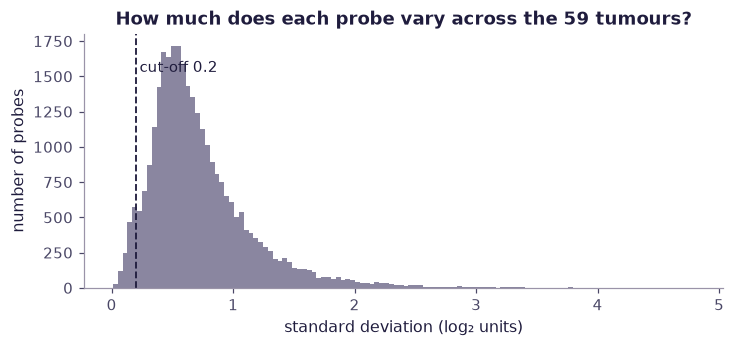

Caption: most probes vary by 0.4–0.9 log₂ units; the thin left tail of nearly flat probes is what we remove.


After dropping near-flat probes (SD < 0.2): 28,592 (1,281 dropped)
This filter ignores the labels, so it cannot bias the comparison (Bourgon et al., 2010).


In [11]:
n0 = expr.shape[0]
expr = expr.dropna()
n_missing = expr.shape[0]
print(f"Probes in matrix: {n0:,} → after dropping probes with any missing value: {n_missing:,} ({n0 - n_missing} dropped)")

SD_CUTOFF = 0.2   # log2 units: less than ~15% typical variation between tumours
sd = expr.std(axis=1)
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(sd, bins=120, color=MUTED)
ax.axvline(SD_CUTOFF, color=INK, ls="--", lw=1.2)
ax.set(title="How much does each probe vary across the 59 tumours?", xlabel="standard deviation (log₂ units)", ylabel="number of probes")
ax.text(SD_CUTOFF + 0.03, ax.get_ylim()[1] * 0.85, f"cut-off {SD_CUTOFF}", color=INK)
save(fig, "03_probe_sd")
print("Caption: most probes vary by 0.4–0.9 log₂ units; the thin left tail of nearly flat probes is what we remove.")

expr = expr[sd >= SD_CUTOFF]
n_var = expr.shape[0]
print(f"After dropping near-flat probes (SD < {SD_CUTOFF}): {n_var:,} ({n_missing - n_var:,} dropped)")
print("This filter ignores the labels, so it cannot bias the comparison (Bourgon et al., 2010).")

**Looking for odd tumours.** For each tumour we compute its median value and how closely its whole profile correlates with the other tumours. We flag a tumour if either number sits more than 3.5 robust standard deviations (MADs) from the typical value.

In [12]:
corr = np.corrcoef(expr.T.values)
meta["median"] = expr.median().values
meta["mean_corr"] = (corr.sum(axis=1) - 1) / (corr.shape[0] - 1)

def robust_z(x):
    mad = stats.median_abs_deviation(x, scale="normal")
    return (x - np.median(x)) / mad

meta["z_median"] = robust_z(meta["median"].values)
meta["z_corr"] = robust_z(meta["mean_corr"].values)
meta["flagged"] = (meta["z_median"].abs() > 3.5) | (meta["z_corr"] < -3.5)
display(meta.sort_values("z_corr").head(6)[["title", "subtype", "median", "mean_corr", "z_median", "z_corr", "flagged"]].round(3))
FLAGGED = meta.index[meta["flagged"]].tolist()
print("Flagged tumours:", FLAGGED or "none")

,title,subtype,median,mean_corr,z_median,z_corr,flagged
geo_accession,,,,,,,
GSM1116198,Luminal B Sample115 rep1,Luminal B,6.608,0.868,-2.191,-2.114,False
GSM1116225,Luminal A Sample142 rep1,Luminal A,6.823,0.871,0.321,-1.944,False
GSM1116207,Luminal B Sample124 rep1,Luminal B,6.796,0.876,0.007,-1.548,False
GSM1116230,Luminal B Sample147 rep1,Luminal B,6.693,0.878,-1.193,-1.472,False
GSM1116192,Luminal B Sample109 rep1,Luminal B,6.867,0.878,0.832,-1.419,False
GSM1116201,Luminal B Sample118 rep1,Luminal B,6.764,0.881,-0.367,-1.247,False


Flagged tumours: none


In [13]:
# Are the two subtypes spread evenly over the lab batches? (If not, batch could pose as biology.)
display(pd.crosstab(meta["subtype"], meta["batch"], margins=True))
chi2, p_batch, *_ = stats.chi2_contingency(pd.crosstab(meta["subtype"], meta["batch"]))
print(f"Chi-square test of subtype vs batch: p = {p_batch:.2f} (a large p means no sign of imbalance)")

batch,1,2,3,4,5,All
subtype,,,,,,
Luminal A,4,6,6,8,5,29
Luminal B,6,7,7,4,6,30
All,10,13,13,12,11,59


Chi-square test of subtype vs batch: p = 0.74 (a large p means no sign of imbalance)


### What we found (Stage 3)
* **Samples:** 155 → **59** (29 Luminal A, 30 Luminal B).
* **Scale:** the values run from about −1.2 to 17 with a median of about 6.6. That is already log₂ (GC-RMA), so we **did not** transform again. The slightly negative values come from the submitters' batch correction.
* **Probes:** 29,873 in the matrix → 29,873 with no missing values (there were none) → **28,592** after removing 1,281 near-flat probes (SD < 0.2).
* **Odd tumours:** see the flag list printed above. The tumour with the weakest correlation to the rest is still within the normal range, so **we kept all 59**. Removing a tumour only because it looks different would bias a small study.
* **Batches:** Luminal A and B are spread fairly evenly across the five batches (chi-square p printed above). So batch is unlikely to masquerade as subtype, and the batch-correction concern from Stage 2 is small here.

---
# Stage 4 · Exploratory data analysis

**What we're doing.** Before any formal test, we look at the data in four plots: the spread of values in each tumour, a map of how similar the tumours are overall (PCA), a heatmap of the most variable genes, and one known gene, *MKI67*, as a sanity check.

**Why it matters.** Plots catch problems that statistics hide, such as a badly normalised sample or swapped labels. They also show the *shape* of the difference. Are Luminal A and B two separate clouds, or one spread with a line drawn through it?

**What to look for below.**
1. *Boxplots:* the medians should line up across tumours. A box far from the others is a red flag.
2. *PCA:* two separate clusters would mean two distinct kinds of tumour. One overlapping spread that leans apart supports our hypothesis of a cut-point on one axis.
3. *Heatmap:* blocks of genes that are high in one subtype and low in the other.
4. ***MKI67*** (a gene that is switched on when cells are actively dividing, so it is used to measure how fast a tumour is growing): it **must be higher in Luminal B**. If it is not, our labels or parsing are wrong.

To name genes we need the **platform annotation**, a table that says which gene each probe on the GPL570 chip measures. The series matrix does not include it, so we download GEO's annotation file for GPL570.

In [14]:
ANNOT_URL = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz"
annot_path = DATA_DIR / "GPL570.annot.gz"
download(ANNOT_URL, annot_path)
with gzip.open(annot_path, "rt", encoding="utf-8") as fh:
    alines = fh.read().splitlines()
a0 = alines.index("!platform_table_begin"); a1 = alines.index("!platform_table_end")
annot = pd.read_csv(io.StringIO("\n".join(alines[a0 + 1:a1])), sep="\t", index_col=0, dtype=str)
annot = annot[["Gene symbol", "Gene title", "Chromosome location", "GO:Process", "GO:Process ID"]].fillna("")
print(f"Annotation rows: {len(annot):,} probes · annotation date: {[l for l in alines[:5] if 'date' in l.lower()][0]}")
symbol = annot["Gene symbol"].reindex(expr.index).fillna("")
symbols_of = symbol.str.split("///")          # a few probes match more than one gene

Using cached GPL570.annot.gz (8.5 MB)


Annotation rows: 54,675 probes · annotation date: !Annotation_date = Aug 09 2016


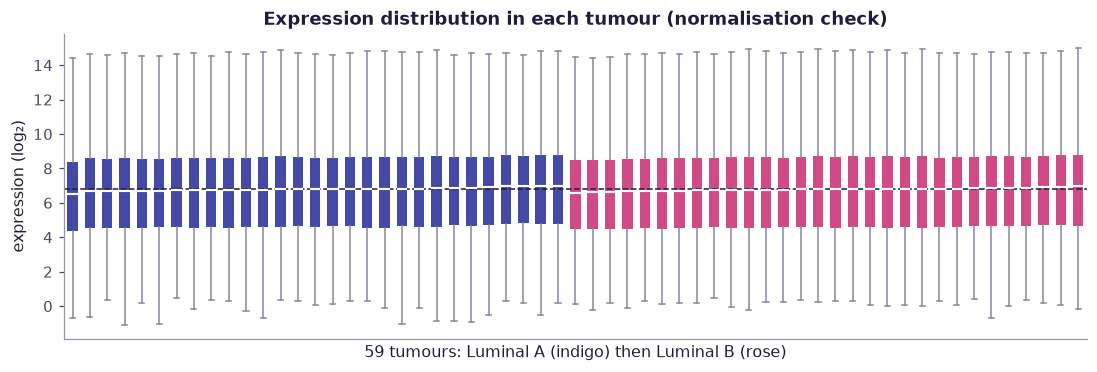

Caption: the medians line up along the dashed line, so the samples are comparably normalised and no tumour is grossly shifted.


In [15]:
# Plot 1 · per-tumour boxplots, Luminal A first then Luminal B
order = meta.sort_values(["subtype", "median"]).index
fig, ax = plt.subplots(figsize=(12, 3.6))
bp = ax.boxplot([expr[s].values for s in order], showfliers=False, widths=0.6, patch_artist=True,
                medianprops=dict(color="white", lw=1.4), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for patch, s in zip(bp["boxes"], order):
    patch.set_facecolor(PAL[meta.loc[s, "subtype"]]); patch.set_edgecolor("none")
ax.axhline(np.median(meta["median"]), color=INK, ls="--", lw=1)
ax.set_xticks([])
ax.set(title="Expression distribution in each tumour (normalisation check)", xlabel="59 tumours: Luminal A (indigo) then Luminal B (rose)", ylabel="expression (log₂)")
save(fig, "04a_sample_boxplots")
print("Caption: the medians line up along the dashed line, so the samples are comparably normalised and no tumour is grossly shifted.")

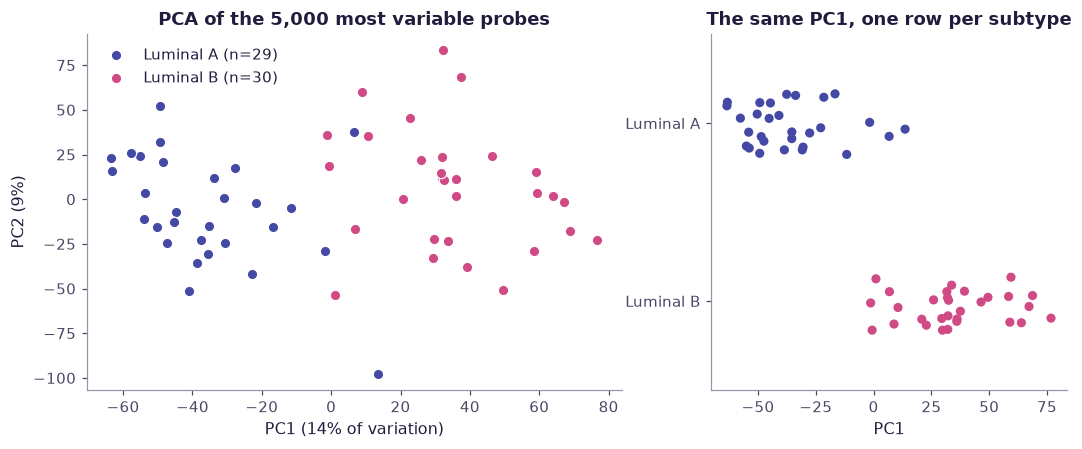

PC1 and PC2 explain 14.5% and 9.0% of the variation.
Overlap zone on PC1 (from the lowest Luminal B to the highest Luminal A): 8 tumours (2 A, 6 B)
Caption: PC1, the largest source of variation, mostly separates the subtypes, with a narrow zone where they overlap; there is no empty gap between them, and PC2 does not separate them at all.


In [16]:
# Plot 2 · PCA on the 5,000 most variable probes
from sklearn.decomposition import PCA
top_var = expr.var(axis=1).sort_values(ascending=False).index[:5000]
Xp = expr.loc[top_var].T
pca = PCA(n_components=5, random_state=SEED).fit(Xp - Xp.mean())
pcs = pca.transform(Xp - Xp.mean())
sign = 1 if pcs[meta["subtype"].values == "Luminal B", 0].mean() > 0 else -1   # put Luminal B on the right
meta["PC1"], meta["PC2"] = sign * pcs[:, 0], pcs[:, 1]
ve = pca.explained_variance_ratio_
lo_b = meta.loc[meta.subtype == "Luminal B", "PC1"].min(); hi_a = meta.loc[meta.subtype == "Luminal A", "PC1"].max()
in_overlap = meta[(meta.PC1 >= lo_b) & (meta.PC1 <= hi_a)]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw=dict(width_ratios=[1.5, 1]))
for st in ["Luminal A", "Luminal B"]:
    m = meta["subtype"] == st
    axes[0].scatter(meta.loc[m, "PC1"], meta.loc[m, "PC2"], s=46, color=PAL[st], edgecolor="white", lw=0.8, label=f"{st} (n={m.sum()})")
axes[0].set(title="PCA of the 5,000 most variable probes", xlabel=f"PC1 ({ve[0]:.0%} of variation)", ylabel=f"PC2 ({ve[1]:.0%})")
axes[0].legend()
sns.stripplot(data=meta, x="PC1", y="subtype", hue="subtype", palette=PAL, ax=axes[1], size=6, jitter=0.18, legend=False)
axes[1].set(title="The same PC1, one row per subtype", xlabel="PC1", ylabel="")
save(fig, "04b_pca")
print(f"PC1 and PC2 explain {ve[0]:.1%} and {ve[1]:.1%} of the variation.")
print(f"Overlap zone on PC1 (from the lowest Luminal B to the highest Luminal A): {len(in_overlap)} tumours "
      f"({(in_overlap.subtype == 'Luminal A').sum()} A, {(in_overlap.subtype == 'Luminal B').sum()} B)")
print("Caption: PC1, the largest source of variation, mostly separates the subtypes, with a narrow zone where they overlap; "
      "there is no empty gap between them, and PC2 does not separate them at all.")

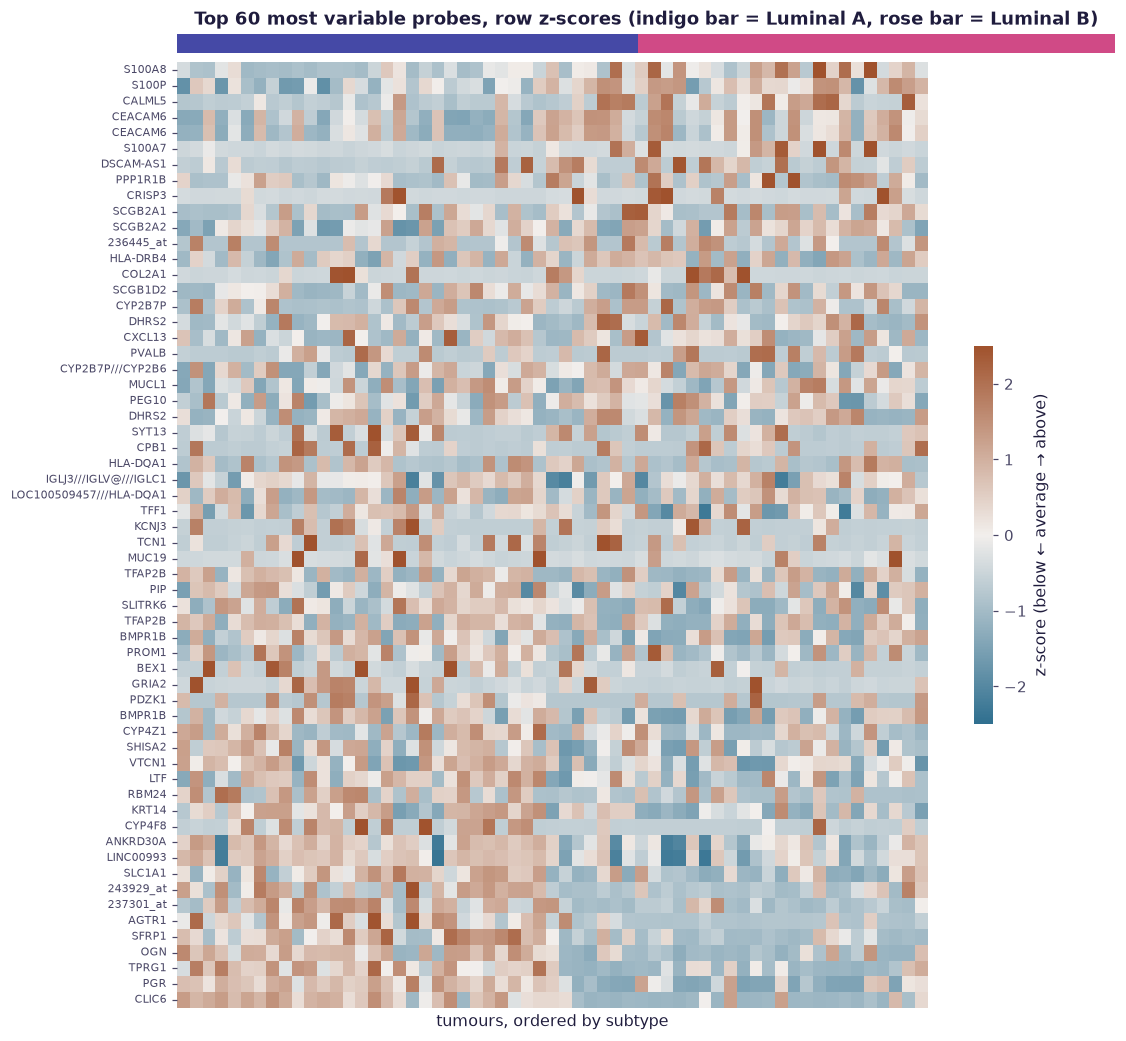

Caption: the most variable genes are mostly NOT cell-division genes. Many (S100, secretoglobin and CEACAM genes) vary within both subtypes; a block at the bottom, including the progesterone receptor PGR, runs higher in Luminal A.


In [17]:
# Plot 3 · heatmap of the 60 most variable probes (row z-scores), tumours ordered by subtype
top60 = expr.var(axis=1).sort_values(ascending=False).index[:60]
z = expr.loc[top60, order]
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0)
row_order = z.iloc[:, :29].mean(axis=1).sub(z.iloc[:, 29:].mean(axis=1)).sort_values().index   # B-high genes at top
z = z.loc[row_order]
labels = [f"{symbol[p] or p}" for p in z.index]
cmap = sns.blend_palette(["#2F6F8F", "#F2EFEC", "#A0522D"], as_cmap=True)
fig, (axc, axh) = plt.subplots(2, 1, figsize=(11, 11.5), gridspec_kw=dict(height_ratios=[0.4, 20], hspace=0.02))
axc.imshow([[0 if meta.loc[s, "subtype"] == "Luminal A" else 1 for s in order]], aspect="auto",
           cmap=plt.matplotlib.colors.ListedColormap([LUM_A, LUM_B]))
axc.set_axis_off(); axc.set_title("Top 60 most variable probes, row z-scores (indigo bar = Luminal A, rose bar = Luminal B)")
sns.heatmap(z, cmap=cmap, center=0, vmin=-2.5, vmax=2.5, ax=axh, xticklabels=False, yticklabels=labels,
            cbar_kws=dict(label="z-score (below ← average → above)", shrink=0.4))
axh.set(xlabel="tumours, ordered by subtype", ylabel="")
axh.tick_params(axis="y", labelsize=7)
save(fig, "04c_heatmap")
cc_top60 = [symbol[p] for p in top60 if any(g in {"MKI67", "TOP2A", "CCNB1", "BIRC5", "UBE2C"} for g in symbols_of[p])]
print("Caption: the most variable genes are mostly NOT cell-division genes. Many (S100, secretoglobin and CEACAM genes) vary within both subtypes;"
      " a block at the bottom, including the progesterone receptor PGR, runs higher in Luminal A.")

**Plot 4 · the MKI67 sanity check.** We look up *MKI67*'s probe IDs in the platform annotation instead of typing them from memory.

,gene (annotation),mean Lum A,mean Lum B,Welch p
probe,,,,
212020_s_at,MKI67,1.9789,2.7613,0.0001
212021_s_at,MKI67,3.2897,6.0438,0.0000
212022_s_at,MKI67,4.0943,6.7700,0.0000
212023_s_at,MKI67,3.5824,4.9762,0.0000


MKI67 probes found in the annotation and present after QC: ['212020_s_at', '212021_s_at', '212022_s_at', '212023_s_at'] → main probe 212022_s_at


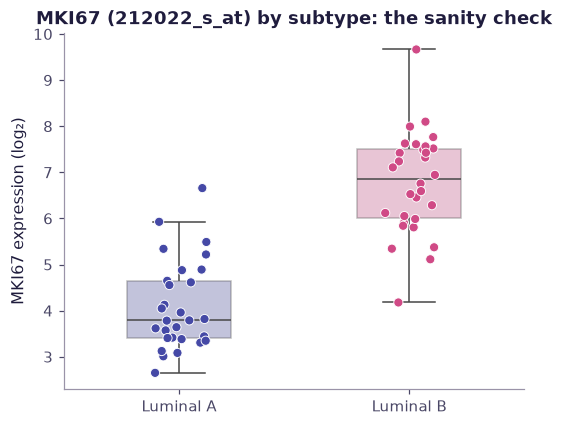

✔ MKI67 is higher in Luminal B by 2.68 log₂ units (6.4× as much message), Welch p = 5.3e-14.
Caption: dividing-cell marker MKI67 is clearly higher in Luminal B, as the subtype definitions require, but the two clouds overlap.


In [18]:
mki_probes = [p for p in expr.index if "MKI67" in symbols_of[p]]
mki_table = pd.DataFrame({
    "probe": mki_probes,
    "gene (annotation)": [symbol[p] for p in mki_probes],
    "mean Lum A": [expr.loc[p, meta.index[meta.subtype == "Luminal A"]].mean() for p in mki_probes],
    "mean Lum B": [expr.loc[p, meta.index[meta.subtype == "Luminal B"]].mean() for p in mki_probes],
}).set_index("probe")
mki_table["Welch p"] = [stats.ttest_ind(expr.loc[p, meta.subtype == "Luminal B"], expr.loc[p, meta.subtype == "Luminal A"], equal_var=False).pvalue for p in mki_probes]
display(mki_table.round(4))
MKI = mki_table[["mean Lum A", "mean Lum B"]].mean(axis=1).idxmax()     # the brightest MKI67 probe
print("MKI67 probes found in the annotation and present after QC:", mki_probes, "→ main probe", MKI)
meta["MKI67"] = expr.loc[MKI].values

fig, ax = plt.subplots(figsize=(5.4, 4.2))
sns.boxplot(data=meta, x="subtype", y="MKI67", hue="subtype", palette=PAL, ax=ax, width=0.45, showfliers=False, boxprops=dict(alpha=0.35), legend=False)
sns.stripplot(data=meta, x="subtype", y="MKI67", hue="subtype", palette=PAL, ax=ax, size=6, jitter=0.12, legend=False, edgecolor="white", linewidth=0.6)
ax.set(title=f"MKI67 ({MKI}) by subtype: the sanity check", xlabel="", ylabel="MKI67 expression (log₂)")
save(fig, "04d_mki67")
diff = mki_table.loc[MKI, "mean Lum B"] - mki_table.loc[MKI, "mean Lum A"]
assert diff > 0, "STOP: MKI67 is not higher in Luminal B. Check labels and parsing."
print(f"✔ MKI67 is higher in Luminal B by {diff:.2f} log₂ units ({2**diff:.1f}× as much message), Welch p = {mki_table.loc[MKI, 'Welch p']:.1e}.")
print("Caption: dividing-cell marker MKI67 is clearly higher in Luminal B, as the subtype definitions require, but the two clouds overlap.")

### What we found (Stage 4)
1. **Boxplots:** the medians line up, so the submitters' normalisation did its job, and no tumour is shifted.
2. **PCA:** the first component (14.5% of the variation) **mostly separates** Luminal A from Luminal B. That is more cleanly than we expected: only a handful of tumours sit in the zone where the groups overlap (count printed above). There is no empty gap, so the tumours form one continuous axis with the labels changing along it. The second component (9%) does not separate the subtypes at all.
3. **Heatmap:** to our surprise, the *most variable* genes are mostly **not** cell-division genes. Many of them (*S100A8*, *S100P*, *CEACAM6*, the secretoglobins *SCGB2A1/2*) vary a lot *within* both subtypes. A block at the bottom runs higher in Luminal A and includes ***PGR***, the progesterone receptor (a hormone receptor; tumours rich in it tend to behave like Luminal A). High variability is not the same as a difference *between* the groups; Stage 5 tests that directly.
4. ***MKI67*** is higher in Luminal B by 2.68 log₂ units (about 6.4× as much message, p ≈ 5×10⁻¹⁴), so **our labels and parsing pass the biology check**. The two clouds still overlap: some Luminal A tumours have more *MKI67* than some Luminal B tumours.

> **Checkpoint (brief §8).** Download ✔, 29/30 split ✔, log decision made from the data ✔, MKI67 check ✔, probe IDs taken from the GPL570 annotation ✔. We only built Stages 5–8 after these checks passed.

---
# Stage 5 · Core analysis: differential expression

**What we're doing.** For each of the ~28,600 probes, we ask whether its average differs between Luminal A and Luminal B more than chance would explain. Then we correct for the fact that we asked that question 28,600 times.

**Why it matters.** This answers Objective 2. The correction is essential. At p < 0.05, about 1 test in 20 comes out "significant" by pure luck. With ~28,600 tests that is **~1,430 false positives** expected even if the two subtypes were identical. The Benjamini–Hochberg method controls the **false discovery rate**: among the genes we call significant, at most about 5% should be false alarms.

**What to look for below.** Good: far more probes pass p < 0.05 than the ~1,430 expected by chance, a histogram of p-values with a spike near zero, and hundreds of probes surviving FDR 5%. Bad: about 1,430 or fewer at p < 0.05 and a flat histogram, which would mean no real difference.

*Method:* Welch's t-test (it does not assume the two groups have equal spread) on the log₂ values, with Mann–Whitney U (which uses ranks only) as a check. **Fold change** = mean(Luminal B) − mean(Luminal A) on the log₂ scale, so +1 means twice as much message in Luminal B.

In [19]:
is_b = (meta["subtype"] == "Luminal B").values
A, B = expr.values[:, ~is_b], expr.values[:, is_b]
t, p = stats.ttest_ind(B, A, axis=1, equal_var=False)
u, p_mw = stats.mannwhitneyu(B, A, axis=1, alternative="two-sided")
de = pd.DataFrame({
    "symbol": symbol.values, "title": annot["Gene title"].reindex(expr.index).fillna("").values,
    "chrom": annot["Chromosome location"].reindex(expr.index).fillna("").values,
    "mean_A": A.mean(axis=1), "mean_B": B.mean(axis=1), "log2FC": B.mean(axis=1) - A.mean(axis=1),
    "t": t, "p": p, "p_mw": p_mw}, index=expr.index)
de["q"] = multipletests(de["p"], method="fdr_bh")[1]
de["q_mw"] = multipletests(de["p_mw"], method="fdr_bh")[1]
de = de.sort_values("p")

n_tests = len(de)
sig = de["q"] < 0.05
print(f"Probes tested: {n_tests:,}")
print(f"Expected 'significant' at p < 0.05 by chance alone: {0.05*n_tests:,.0f}")
print(f"Actually at p < 0.05: {(de.p < 0.05).sum():,}  ({(de.p < 0.05).sum()/(0.05*n_tests):.1f}× the chance level)")
print(f"Pass FDR < 0.05 (Benjamini–Hochberg): {sig.sum():,} probes  →  {(sig & (de.log2FC > 0)).sum():,} higher in Luminal B, {(sig & (de.log2FC < 0)).sum():,} higher in Luminal A")
print(f"Distinct genes among them: {de.loc[sig, 'symbol'].str.split('///').explode().replace('', np.nan).dropna().nunique():,}")
print(f"For comparison, the much stricter Bonferroni correction keeps {(de.p < 0.05/n_tests).sum():,} probes.")

Probes tested: 28,592
Expected 'significant' at p < 0.05 by chance alone: 1,430
Actually at p < 0.05: 11,305  (7.9× the chance level)
Pass FDR < 0.05 (Benjamini–Hochberg): 8,269 probes  →  4,122 higher in Luminal B, 4,147 higher in Luminal A


Distinct genes among them: 5,631
For comparison, the much stricter Bonferroni correction keeps 804 probes.


In [20]:
# Probe → gene mapping: does the annotation actually give symbols for most probes?
match_rate = (symbol != "").mean()
print(f"Probes with a gene symbol: {(symbol != '').sum():,} of {len(symbol):,} = {match_rate:.1%}")
print(f"Among the FDR-significant probes: {(de.loc[sig, 'symbol'] != '').mean():.1%} have a symbol")

Probes with a gene symbol: 25,699 of 28,592 = 89.9%
Among the FDR-significant probes: 92.1% have a symbol


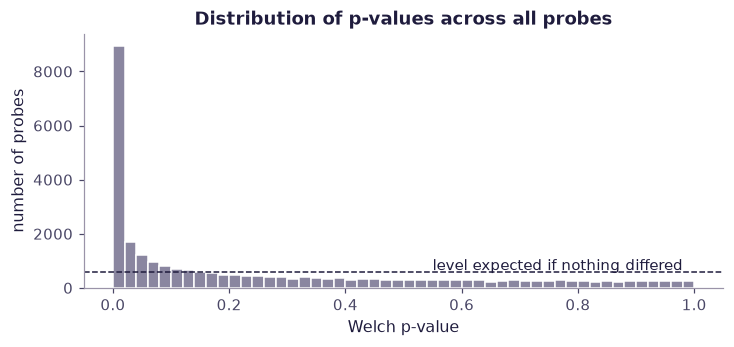

Caption: the tall bar at the left is the real signal; the flat floor is what pure chance looks like.


In [21]:
# p-value histogram: a flat floor (true nulls) plus a spike near 0 (real differences)
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(de["p"], bins=50, color=MUTED, edgecolor="white")
ax.axhline(n_tests / 50, color=INK, ls="--", lw=1)
ax.set(title="Distribution of p-values across all probes", xlabel="Welch p-value", ylabel="number of probes")
ax.text(0.55, n_tests / 50 * 1.15, "level expected if nothing differed", color=INK)
save(fig, "05a_pvalue_histogram")
print("Caption: the tall bar at the left is the real signal; the flat floor is what pure chance looks like.")

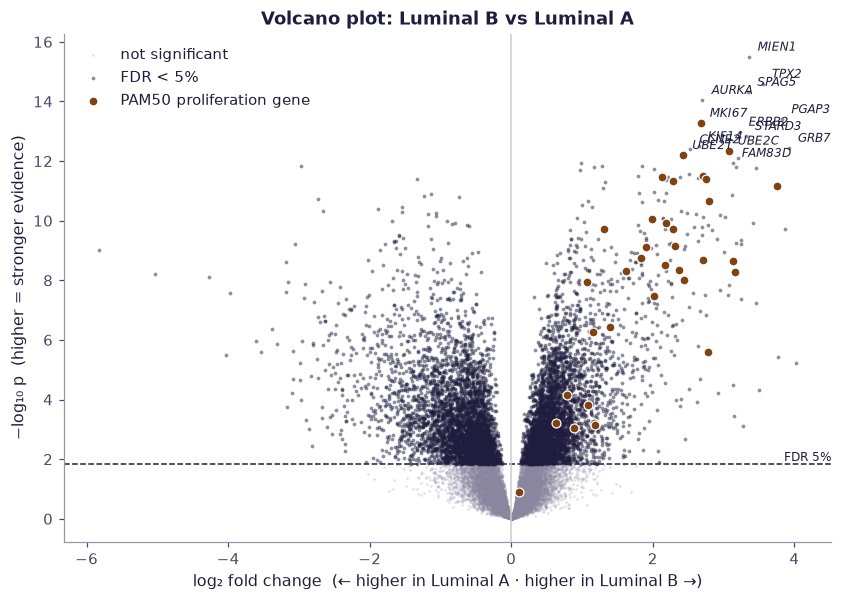

Caption: the strongest differences sit at the upper right (higher in Luminal B), and brown proliferation genes crowd that corner.


In [22]:
# Volcano plot. Brown = the 21 declared PAM50 proliferation genes.
PAM50_PROLIF = ["ANLN", "BIRC5", "CCNB1", "CCNE1", "CDC20", "CDC6", "NUF2", "CENPF", "CEP55", "EXO1", "KIF2C",
                "NDC80", "MELK", "MKI67", "MYBL2", "ORC6", "PTTG1", "RRM2", "TYMS", "UBE2C", "UBE2T"]
ALIASES = {"CDCA1": "NUF2", "KNTC2": "NDC80", "ORC6L": "ORC6"}
in_pam50 = de["symbol"].str.split("///").apply(lambda gs: any(ALIASES.get(g, g) in PAM50_PROLIF for g in gs))
de["pam50"] = in_pam50

q_line = -np.log10(de.loc[sig, "p"].max())
fig, ax = plt.subplots(figsize=(9, 6))
ns = ~sig
ax.scatter(de.loc[ns, "log2FC"], -np.log10(de.loc[ns, "p"]), s=3, color=MUTED, alpha=0.25, lw=0, label="not significant")
ax.scatter(de.loc[sig & ~in_pam50, "log2FC"], -np.log10(de.loc[sig & ~in_pam50, "p"]), s=6, color=INK, alpha=0.5, lw=0, label="FDR < 5%")
ax.scatter(de.loc[in_pam50, "log2FC"], -np.log10(de.loc[in_pam50, "p"]), s=34, color=PROLIF, edgecolor="white", lw=0.8, label="PAM50 proliferation gene")
ax.axhline(q_line, color=INK, ls="--", lw=1); ax.axvline(0, color="#CCC", lw=1)
labelled = de[de.symbol != ""].drop_duplicates("symbol").head(14)
for pid, r in labelled.iterrows():
    ax.annotate(r.symbol, (r.log2FC, -np.log10(r.p)), xytext=(6 if r.log2FC > 0 else -6, 4), textcoords="offset points",
                ha="left" if r.log2FC > 0 else "right", fontsize=8, fontstyle="italic", color=INK)
ax.set(title="Volcano plot: Luminal B vs Luminal A", xlabel="log₂ fold change  (← higher in Luminal A · higher in Luminal B →)", ylabel="−log₁₀ p  (higher = stronger evidence)")
ax.text(ax.get_xlim()[1], q_line, " FDR 5%", va="bottom", ha="right", fontsize=8)
ax.legend(loc="upper left")
save(fig, "05b_volcano")
print("Caption: the strongest differences sit at the upper right (higher in Luminal B), and brown proliferation genes crowd that corner.")

**Results table: top 30 probes.** Means are on the log₂ scale. *Fold* converts the log₂ fold change back to "times as much".

In [23]:
top30 = de.head(30).copy()
top30["fold"] = np.where(top30.log2FC > 0, 2**top30.log2FC, -(2**-top30.log2FC))
show = top30[["symbol", "mean_A", "mean_B", "log2FC", "fold", "p", "q", "pam50"]].rename(columns={"mean_A": "mean Lum A", "mean_B": "mean Lum B", "q": "q (BH)", "pam50": "PAM50 prolif?"})
show.index.name = "probe"
display(show.style.format({"mean Lum A": "{:.2f}", "mean Lum B": "{:.2f}", "log2FC": "{:+.2f}", "fold": "{:+.1f}×", "p": "{:.1e}", "q (BH)": "{:.1e}"}))
Path("results").mkdir(exist_ok=True)
de.head(2000).to_csv("results/differential_expression_top2000.csv")
print("Saved the top 2,000 probes to results/differential_expression_top2000.csv")

,symbol,mean Lum A,mean Lum B,log2FC,fold,p,q (BH),PAM50 prolif?
probe,,,,,,,,
224447_s_at,MIEN1,9.07,12.42,+3.35,+10.2×,3.2e-16,9.1e-12,False
210052_s_at,TPX2,4.25,7.81,+3.55,+11.7×,2.6e-15,3.7e-11,False
203145_at,SPAG5,3.49,6.83,+3.35,+10.2×,4.8e-15,4.6e-11,False
204092_s_at,AURKA,4.08,6.78,+2.70,+6.5×,9.0e-15,6.4e-11,False
55616_at,PGAP3,7.11,10.94,+3.83,+14.2×,4.0e-14,2.3e-10,False
212022_s_at,MKI67,4.09,6.77,+2.68,+6.4×,5.3e-14,2.5e-10,True
216836_s_at,ERBB2,10.34,13.56,+3.23,+9.4×,1.0e-13,4.3e-10,False
208079_s_at,AURKA,5.25,8.23,+2.98,+7.9×,1.3e-13,4.6e-10,False
202991_at,STARD3,6.65,9.96,+3.31,+9.9×,1.5e-13,4.6e-10,False


Saved the top 2,000 probes to results/differential_expression_top2000.csv


In [24]:
agree = ((de.q < 0.05) == (de.q_mw < 0.05)).mean()
both = ((de.q < 0.05) & (de.q_mw < 0.05)).sum()
print(f"Mann–Whitney U (rank-based) agrees with Welch on significant / not significant for {agree:.1%} of probes.")
print(f"{both:,} probes are significant under both tests; Mann–Whitney alone: {(de.q_mw < 0.05).sum():,}.")

Mann–Whitney U (rank-based) agrees with Welch on significant / not significant for 94.9% of probes.
7,525 probes are significant under both tests; Mann–Whitney alone: 8,229.


### What we found (Stage 5)
* There is a **real, large difference**. **11,305** probes pass p < 0.05, against the ~1,430 that chance alone would give (7.9×), and the p-value histogram has a tall spike at zero.
* After Benjamini–Hochberg correction, **8,269 probes (5,631 distinct genes) pass FDR < 5%**. About 1 in 20 of those may be a false alarm, which is the price of a 5% FDR. Even the far stricter Bonferroni correction keeps 804.
* **Direction:** the significant probes split almost evenly: 4,122 are higher in Luminal B and 4,147 higher in Luminal A. However, the *strongest* differences (top of the volcano) are almost all higher in Luminal B.
* **What sits at the top:** the top 15 probes are two groups. One is **cell-division genes** (*TPX2*, *SPAG5*, *AURKA*, *MKI67*, *KIF14*, *CCNE2*, *UBE2C*, *UBE2T*), as our hypothesis predicted. The other, which we did not predict, is genes sitting side by side on chromosome 17: ***MIEN1*, *PGAP3*, *ERBB2*, *STARD3*, *GRB7***. We come back to this in Stage 6.
* **Robustness:** Mann–Whitney U reaches the same significant / not-significant verdict for 94.9% of probes, so the result does not hinge on the t-test's assumptions.
* **Mapping:** the GPL570 annotation gives a gene symbol for **89.9%** of the probes we analysed (92.1% of the significant ones). The rest are probes for unnamed transcripts.

---
# Stage 6 · Biological interpretation

**What we're doing.** We ask what the significant genes *do*. First we test which biological processes are over-represented among them (enrichment). Then we do the measurement that makes this project honest: we count how much of the signal is cell-division genes, using the gene sets we **declared in Stage 1 before seeing any results**.

**Why it matters.** This answers Objective 3. A list of 2,000 gene names explains nothing on its own. We need to know whether it is one story (cell division) or many. This is also the test of our hypothesis.

**What to look for below.** If the hypothesis is right: cell-division processes top the enrichment list for genes higher in Luminal B, most of the top 50 probes are cell-cycle genes, and the share of cell-cycle genes among significant probes is far above their share on the chip. If it is wrong: a mix of unrelated themes, and a cell-cycle share no higher than background.

In [25]:
# Declared sets (Stage 1) → probes
go_ids = annot["GO:Process ID"].reindex(expr.index).fillna("")
go_names = annot["GO:Process"].reindex(expr.index).fillna("")
CELL_CYCLE_GO = {"GO:0007049", "GO:0051301"}     # cell cycle, cell division (direct annotations)
in_cc = go_ids.str.split("///").apply(lambda ids: bool(CELL_CYCLE_GO & set(ids))) | in_pam50.reindex(expr.index)
de["cell_cycle"] = in_cc.reindex(de.index)

found = sorted({ALIASES.get(g, g) for gs in de.loc[de.pam50, "symbol"].str.split("///") for g in gs} & set(PAM50_PROLIF))
print(f"PAM50 proliferation genes found on the chip after QC: {len(found)}/21 ({de.pam50.sum()} probes)")
missing = sorted(set(PAM50_PROLIF) - set(found)); print("Missing:", missing or "none")
print(f"Probes annotated to GO cell cycle / cell division (or PAM50): {int(in_cc.sum()):,} of {len(in_cc):,} ({in_cc.mean():.1%} of the chip)")
print("Note: GO counts use direct annotations only (no inheritance from child terms), so they are a conservative count.")

PAM50 proliferation genes found on the chip after QC: 21/21 (35 probes)
Missing: none
Probes annotated to GO cell cycle / cell division (or PAM50): 850 of 28,592 (3.0% of the chip)
Note: GO counts use direct annotations only (no inheritance from child terms), so they are a conservative count.


In [26]:
# How much of the signal is proliferation?
share = {}
for n in (50, 100, 500):
    top = de.head(n)
    share[n] = dict(pam50=int(top.pam50.sum()), cell_cycle=int(top.cell_cycle.sum()))
    print(f"Top {n:>3} probes: {top.cell_cycle.sum():>3} cell-cycle/division ({top.cell_cycle.mean():.0%}), of which {top.pam50.sum()} PAM50 proliferation")

# Enrichment test: are cell-cycle probes over-represented among FDR-significant probes?
table = pd.crosstab(de.q < 0.05, de.cell_cycle)
odds, p_enrich = stats.fisher_exact(table.values[::-1, ::-1], alternative="greater")
cc_sig, cc_bg = de.loc[de.q < 0.05, "cell_cycle"].mean(), de.cell_cycle.mean()
print(f"\nCell-cycle share among significant probes: {cc_sig:.1%} vs {cc_bg:.1%} on the whole chip → odds ratio {odds:.1f}, Fisher p = {p_enrich:.1e}")
top_b = de[(de.q < 0.05) & (de.log2FC > 0)].head(100)
print(f"Among the 100 strongest probes higher in Luminal B: {top_b.cell_cycle.mean():.0%} are cell-cycle genes.")

Top  50 probes:  22 cell-cycle/division (44%), of which 9 PAM50 proliferation
Top 100 probes:  30 cell-cycle/division (30%), of which 13 PAM50 proliferation
Top 500 probes:  66 cell-cycle/division (13%), of which 25 PAM50 proliferation

Cell-cycle share among significant probes: 4.3% vs 3.0% on the whole chip → odds ratio 1.8, Fisher p = 2.0e-15
Among the 100 strongest probes higher in Luminal B: 35% are cell-cycle genes.


**Which processes are over-represented?** We run an *enrichment* test for every Gene Ontology biological process in the annotation file. For each process we ask: are its genes found among our significant genes more often than chance predicts? (This is a one-sided Fisher / hypergeometric test, with Benjamini–Hochberg correction across processes.) It runs offline, so it is fully reproducible. We test genes higher in Luminal B and genes higher in Luminal A separately, because they may tell different stories.

In [27]:
# Gene-level universe: one entry per gene symbol among analysed probes
gene_go = {}
for pid in expr.index:
    ids, names = go_ids[pid].split("///"), go_names[pid].split("///")
    for g in symbols_of[pid]:
        if g:
            gene_go.setdefault(g, {}).update({i: n for i, n in zip(ids, names) if i})
universe = set(gene_go)
term_genes, term_name = {}, {}
for g, terms in gene_go.items():
    for tid, tname in terms.items():
        term_genes.setdefault(tid, set()).add(g); term_name[tid] = tname

def genes_of(frame):
    return {g for gs in frame["symbol"].str.split("///") for g in gs if g}

def go_enrichment(hits, min_size=10, max_size=500):
    hits = hits & universe; N, n = len(universe), len(hits)
    rows = []
    for tid, members in term_genes.items():
        K = len(members)
        if min_size <= K <= max_size:
            k = len(members & hits)
            if k >= 3:
                rows.append((tid, term_name[tid], k, K, stats.hypergeom.sf(k - 1, N, K, n), sorted(members & hits)))
    res = pd.DataFrame(rows, columns=["id", "term", "k", "K", "p", "genes"])
    res["q"] = multipletests(res["p"], method="fdr_bh")[1]
    return res.sort_values("p")

up_b_genes = genes_of(de[(de.q < 0.05) & (de.log2FC > 0)])
up_a_genes = genes_of(de[(de.q < 0.05) & (de.log2FC < 0)])
print(f"Universe: {len(universe):,} genes · significant and higher in Luminal B: {len(up_b_genes):,} · higher in Luminal A: {len(up_a_genes):,}")
enr_b, enr_a = go_enrichment(up_b_genes), go_enrichment(up_a_genes)
for name, res in (("Higher in Luminal B", enr_b), ("Higher in Luminal A", enr_a)):
    print(f"\n{name}: {(res.q < 0.05).sum()} GO processes at FDR < 5%. Top 10:")
    display(res.head(10).assign(overlap=lambda d: d.k.astype(str) + "/" + d.K.astype(str), q=lambda d: d.q.map("{:.1e}".format))[["id", "term", "overlap", "q"]])

Universe: 15,026 genes · significant and higher in Luminal B: 3,106 · higher in Luminal A: 2,566



Higher in Luminal B: 122 GO processes at FDR < 5%. Top 10:


,id,term,overlap,q
199,GO:0051301,cell division,142/318,3.0e-19
720,GO:0031145,anaphase-promoting complex-dependent catabolic process,51/81,1.1e-13
729,GO:0006521,regulation of cellular amino acid metabolic process,37/51,1.1e-12
346,GO:0034080,CENP-A containing nucleosome assembly,32/42,5.2e-12
728,GO:0051437,positive regulation of ubiquitin-protein ligase activity involved in regulation of mitotic cell cycle transition,48/80,5.2e-12
200,GO:0007067,mitotic nuclear division,101/240,7.2e-12
723,GO:0051436,negative regulation of ubiquitin-protein ligase activity involved in mitotic cell cycle,46/76,8.2e-12
348,GO:0007062,sister chromatid cohesion,54/107,1.2e-09
13,GO:0006260,DNA replication,64/139,2.4e-09
1030,GO:0007059,chromosome segregation,35/60,2.8e-08



Higher in Luminal A: 87 GO processes at FDR < 5%. Top 10:


,id,term,overlap,q
550,GO:0006614,SRP-dependent cotranslational protein targeting to membrane,87/140,7.4e-30
553,GO:0019083,viral transcription,93/164,6.9e-28
552,GO:0006413,translational initiation,101/189,1.1e-27
298,GO:0000184,"nuclear-transcribed mRNA catabolic process, nonsense-mediated decay",94/182,2.6e-24
503,GO:0006364,rRNA processing,104/275,2.7e-14
540,GO:0006412,translation,98/257,9.3e-14
2,GO:0030198,extracellular matrix organization,64/165,4.4e-09
529,GO:0007517,muscle organ development,30/72,1.3e-04
466,GO:0007507,heart development,50/154,3.2e-04
1041,GO:0045725,positive regulation of glycogen biosynthetic process,9/11,6.6e-04


**Optional online cross-check: MSigDB Hallmark sets via Enrichr.** The Hallmark collection is 50 curated summaries of well-known biological states, such as "G2M checkpoint" (cells preparing to divide) and "estrogen response". This step needs internet. If Enrichr is unreachable, the notebook says so and carries on, because nothing else depends on it.

In [28]:
hallmark = {}
try:
    import gseapy as gp
    for name, genes in (("upInB", up_b_genes), ("upInA", up_a_genes)):
        top_genes = list(de[de.symbol.isin(genes)].drop_duplicates("symbol").symbol.head(300))
        r = gp.enrichr(gene_list=top_genes, gene_sets=["MSigDB_Hallmark_2020"], organism="human", outdir=None).results
        hallmark[name] = r.sort_values("Adjusted P-value")
        print(f"\nHallmark sets for the top 300 genes {'higher in Luminal B' if name == 'upInB' else 'higher in Luminal A'}:")
        display(r.sort_values("Adjusted P-value").head(6)[["Term", "Overlap", "Adjusted P-value"]])
except Exception as err:
    print("Enrichr cross-check skipped (no connection or service error):", type(err).__name__, str(err)[:120])


Hallmark sets for the top 300 genes higher in Luminal B:


,Term,Overlap,Adjusted P-value
0,G2-M Checkpoint,54/200,4.069810e-51
1,E2F Targets,51/200,4.598443e-47
2,Mitotic Spindle,28/199,3.310103e-18
3,mTORC1 Signaling,26/200,3.678674e-16
4,Myc Targets V1,17/200,7.590322e-08
5,Spermatogenesis,9/135,1.329815e-03



Hallmark sets for the top 300 genes higher in Luminal A:


,Term,Overlap,Adjusted P-value
0,Estrogen Response Early,10/200,0.016884
1,Epithelial Mesenchymal Transition,10/200,0.016884
2,UV Response Dn,8/144,0.018636
3,Estrogen Response Late,9/200,0.030681
4,TGF-beta Signaling,4/54,0.057332
5,Myogenesis,8/200,0.057332


**A proliferation score for every tumour.** We give each tumour one number for how strongly its cell-division genes are switched on. We use the brightest probe for each of the 21 declared genes, convert each to a z-score (how many standard deviations above or below that gene's average), and average them. The score uses **no labels**, so it can be computed for any new tumour.

Representative probe per PAM50 proliferation gene (looked up in the GPL570 annotation):
TYMS=202589_at, PTTG1=203554_x_at, RRM2=201890_at, CCNB1=214710_s_at, UBE2C=202954_at, ORC6=219105_x_at, MELK=204825_at, CENPF=207828_s_at, UBE2T=223229_at, ANLN=222608_s_at, NDC80=204162_at, NUF2=223381_at, CDC20=202870_s_at, BIRC5=202095_s_at, MYBL2=201710_at, MKI67=212022_s_at, CCNE1=213523_at, CEP55=218542_at, KIF2C=209408_at, CDC6=203968_s_at, EXO1=204603_at

The proliferation score alone ranks a random Luminal B above a random Luminal A 97% of the time (AUC 0.97).
Best single cut-point chosen with hindsight on all 59 tumours: score ≥ 0.07 → 93% agree with the label (optimistic; Stage 7 gives honest numbers).


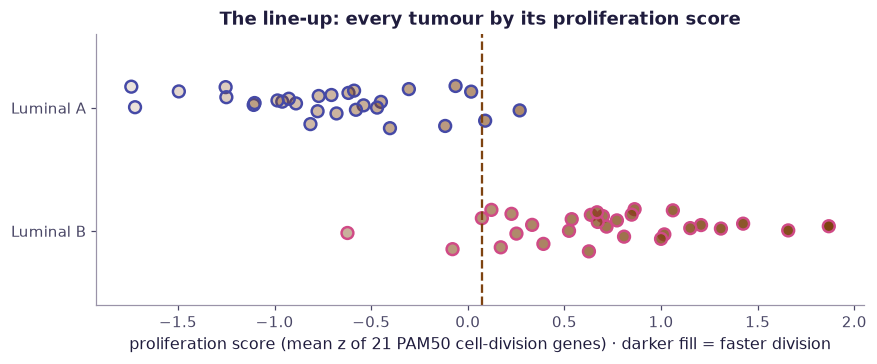

Caption: Luminal B sits further right on average, but the lanes overlap, so any line drawn through this spread misplaces some tumours.


In [29]:
rep = (de[de.pam50].assign(gene=lambda d: d.symbol.str.split("///").str[0].map(lambda g: ALIASES.get(g, g)),
                           mean=lambda d: (d.mean_A + d.mean_B) / 2)
          .sort_values("mean", ascending=False).drop_duplicates("gene"))
PROLIF_PROBES = rep.index.tolist()
print("Representative probe per PAM50 proliferation gene (looked up in the GPL570 annotation):")
print(", ".join(f"{g}={p}" for g, p in zip(rep.gene, rep.index)))
zp = expr.loc[PROLIF_PROBES]
zp = zp.sub(zp.mean(axis=1), axis=0).div(zp.std(axis=1), axis=0)
meta["prolif"] = zp.mean().values

auc_score = stats.mannwhitneyu(meta.prolif[is_b], meta.prolif[~is_b]).statistic / (is_b.sum() * (~is_b).sum())
cuts = np.sort(meta.prolif.values)
acc_at = [((meta.prolif >= c) == is_b).mean() for c in cuts]
best_cut = float(cuts[int(np.argmax(acc_at))])
print(f"\nThe proliferation score alone ranks a random Luminal B above a random Luminal A {auc_score:.0%} of the time (AUC {auc_score:.2f}).")
print(f"Best single cut-point chosen with hindsight on all 59 tumours: score ≥ {best_cut:.2f} → {max(acc_at):.0%} agree with the label (optimistic; Stage 7 gives honest numbers).")

fig, ax = plt.subplots(figsize=(9, 3.2))
for st, y0 in (("Luminal A", 1), ("Luminal B", 0)):
    m = meta.subtype == st
    ax.scatter(meta.loc[m, "prolif"], y0 + np.random.default_rng(SEED).uniform(-0.18, 0.18, m.sum()),
               s=60, c=[plt.matplotlib.colors.to_rgba(PROLIF, 0.15 + 0.85 * (v - cuts[0]) / (cuts[-1] - cuts[0])) for v in meta.loc[m, "prolif"]],
               edgecolor=PAL[st], lw=1.6)
ax.axvline(best_cut, color=PROLIF, ls="--", lw=1.5)
ax.set_yticks([0, 1], ["Luminal B", "Luminal A"]); ax.set_ylim(-0.6, 1.6)
ax.set(title="The line-up: every tumour by its proliferation score", xlabel="proliferation score (mean z of 21 PAM50 cell-division genes) · darker fill = faster division")
save(fig, "06a_lineup")
print("Caption: Luminal B sits further right on average, but the lanes overlap, so any line drawn through this spread misplaces some tumours.")

**Does anything survive once we account for proliferation?** For every probe we fit a small regression: *expression = subtype + proliferation score*. If a gene differs between the subtypes only because Luminal B divides faster, its subtype effect vanishes once the score is in the model. Genes whose subtype effect survives are differences **beyond proliferation**.

In [30]:
D = np.column_stack([np.ones(len(meta)), is_b.astype(float), meta.prolif.values])
Y = expr.values.T                                           # samples × probes
beta, *_ = np.linalg.lstsq(D, Y, rcond=None)
resid = Y - D @ beta
dof = D.shape[0] - D.shape[1]
se_b1 = np.sqrt((resid ** 2).sum(axis=0) / dof * np.linalg.inv(D.T @ D)[1, 1])
p_adj = 2 * stats.t.sf(np.abs(beta[1] / se_b1), dof)
adj = pd.DataFrame({"symbol": symbol.values, "subtype_effect": beta[1], "p": p_adj}, index=expr.index)
adj["q"] = multipletests(adj.p, method="fdr_bh")[1]
adj = adj.sort_values("p")
surv = adj[adj.q < 0.05]
print(f"Probes significant for subtype BEFORE adjusting for proliferation: {(de.q < 0.05).sum():,}")
print(f"Probes still significant AFTER adjusting (FDR < 5%): {len(surv):,}  "
      f"({(surv.subtype_effect > 0).sum()} higher in Luminal B, {(surv.subtype_effect < 0).sum()} higher in Luminal A)")
display(surv.head(15).round({"subtype_effect": 2}).assign(p=lambda d: d.p.map("{:.1e}".format), q=lambda d: d.q.map("{:.1e}".format)))

Probes significant for subtype BEFORE adjusting for proliferation: 8,269
Probes still significant AFTER adjusting (FDR < 5%): 64  (21 higher in Luminal B, 43 higher in Luminal A)


,symbol,subtype_effect,p,q
ID_REF,,,,
224447_s_at,MIEN1,3.00,1.1e-08,1.3e-04
216836_s_at,ERBB2,3.57,1.2e-08,1.3e-04
210761_s_at,GRB7,4.40,1.3e-08,1.3e-04
55616_at,PGAP3,3.77,4.0e-08,2.9e-04
202991_at,STARD3,2.98,2.2e-07,1.3e-03
221811_at,PGAP3,3.00,2.9e-07,1.4e-03
238625_at,C1orf168,-3.82,1.8e-06,7.1e-03
205933_at,SETBP1,-2.95,2.0e-06,7.1e-03
225297_at,HAUS1,-1.42,2.2e-06,7.1e-03


### An unplanned finding: a second dividing line *(exploratory)*
The volcano plot and the adjusted analysis both point at genes that are **not** about cell division: *ERBB2*, *GRB7*, *STARD3*, *PGAP3* and *MIEN1*. They sit next to each other on chromosome 17, in band **17q12**. In some breast tumours this stretch of DNA is copied many times over (*amplified*), so every gene on it is over-expressed together. *ERBB2* makes the protein **HER2**, a growth-signal receptor, and whether a tumour is "HER2-positive" is a routine clinical test that decides whether the patient gets anti-HER2 drugs.

Why might it separate *luminal* tumours? Under the widely used 2011 St Gallen definitions, an oestrogen-receptor-positive tumour that is also HER2-positive is classed as **Luminal B whatever its proliferation** (Goldhirsch *et al.*, 2011). The GEO record does not say which definition the submitters used, so we measure it instead of assuming.

**Honesty note:** we chose these five genes *after* seeing the results, so everything in this section is **exploratory**. It generates a hypothesis and is not a pre-planned test.

,probe,chromosome,n_probes,mean_A,mean_B
gene,,,,,
ERBB2,216836_s_at,17q12,3,10.34,13.56
GRB7,210761_s_at,17q12,1,5.79,9.71
STARD3,202991_at,17q11-q12,1,6.65,9.96
PGAP3,55616_at,17q12,2,7.11,10.94
MIEN1,224447_s_at,17q12,1,9.07,12.42


Chromosome bands of the five genes: ['17q11-q12', '17q12']
HER2-amplicon score AUC: 0.99 (proliferation score: 0.97) · best hindsight cut -0.51 → 95% agree
ERBB2 (216836_s_at): 25 of 30 Luminal B tumours are above the HIGHEST Luminal A value
Correlation between the proliferation score and the HER2-amplicon score: r = 0.69
Luminal B tumours on the 'slow' side of the proliferation line: 2; of those, 2 are HER2-amplicon high
Rule 'Luminal B if fast OR HER2-high' (both cuts chosen with hindsight): 93% agree with the label (4 disagree) · optimistic, not cross-validated


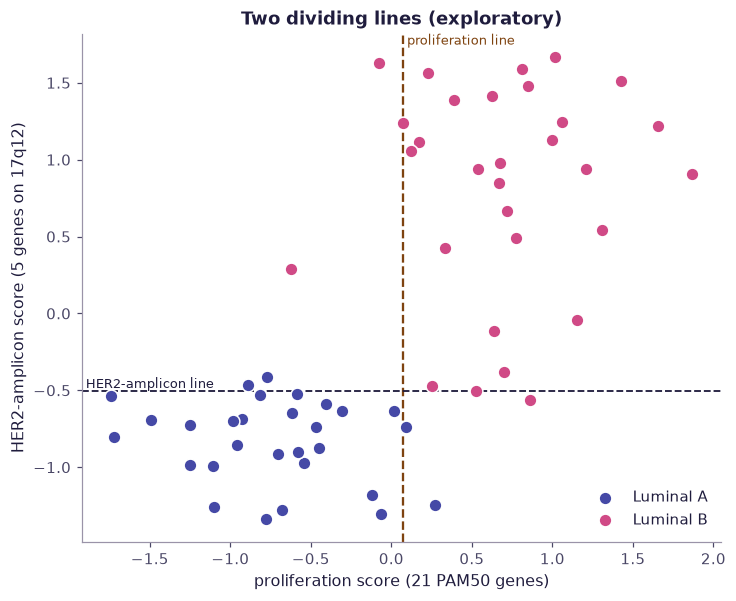

Caption: Luminal B tumours sit right of the proliferation line, above the HER2 line, or both; Luminal A tumours sit low on both.


In [31]:
AMPLICON = ["ERBB2", "GRB7", "STARD3", "PGAP3", "MIEN1"]
chrom = annot["Chromosome location"].reindex(expr.index).fillna("")
amp_rows = []
for g in AMPLICON:
    pr = [p for p in expr.index if g in symbols_of[p]]
    best = max(pr, key=lambda p: expr.loc[p].mean())
    amp_rows.append(dict(gene=g, probe=best, chromosome=chrom[best], n_probes=len(pr),
                         mean_A=expr.loc[best, ~is_b].mean(), mean_B=expr.loc[best, is_b].mean()))
amp_tab = pd.DataFrame(amp_rows).set_index("gene")
display(amp_tab.round(2))
AMP_PROBES = amp_tab.probe.tolist()
za = expr.loc[AMP_PROBES]
za = za.sub(za.mean(axis=1), axis=0).div(za.std(axis=1), axis=0)
meta["her2"] = za.mean().values
meta["ERBB2"] = expr.loc[amp_tab.at["ERBB2", "probe"]].values

auc_her2 = stats.mannwhitneyu(meta.her2[is_b], meta.her2[~is_b]).statistic / (is_b.sum() * (~is_b).sum())
hcuts = np.sort(meta.her2.values)
acc_h = [((meta.her2 >= c) == is_b).mean() for c in hcuts]
her2_cut = float(hcuts[int(np.argmax(acc_h))])
r_ph = np.corrcoef(meta.prolif, meta.her2)[0, 1]
above = int((meta.loc[is_b, "ERBB2"] > meta.loc[~is_b, "ERBB2"].max()).sum())
print(f"Chromosome bands of the five genes: {sorted(set(amp_tab.chromosome))}")
print(f"HER2-amplicon score AUC: {auc_her2:.2f} (proliferation score: {auc_score:.2f}) · best hindsight cut {her2_cut:.2f} → {max(acc_h):.0%} agree")
print(f"ERBB2 ({amp_tab.at['ERBB2', 'probe']}): {above} of {is_b.sum()} Luminal B tumours are above the HIGHEST Luminal A value")
print(f"Correlation between the proliferation score and the HER2-amplicon score: r = {r_ph:.2f}")

slow_b = meta[is_b & (meta.prolif < best_cut)]
rescued = int((slow_b.her2 >= her2_cut).sum())
or_rule = ((meta.prolif >= best_cut) | (meta.her2 >= her2_cut)) == is_b
print(f"Luminal B tumours on the 'slow' side of the proliferation line: {len(slow_b)}; of those, {rescued} are HER2-amplicon high")
print(f"Rule 'Luminal B if fast OR HER2-high' (both cuts chosen with hindsight): {or_rule.mean():.0%} agree with the label "
      f"({(~or_rule).sum()} disagree) · optimistic, not cross-validated")

fig, ax = plt.subplots(figsize=(7.5, 6))
for st in ["Luminal A", "Luminal B"]:
    m = meta.subtype == st
    ax.scatter(meta.loc[m, "prolif"], meta.loc[m, "her2"], s=70, color=PAL[st], edgecolor="white", lw=1, label=st, zorder=3)
ax.axvline(best_cut, color=PROLIF, ls="--", lw=1.5); ax.axhline(her2_cut, color=INK, ls="--", lw=1.2)
ax.text(best_cut, ax.get_ylim()[1], " proliferation line", color=PROLIF, va="top", fontsize=8.5)
ax.text(ax.get_xlim()[0], her2_cut, " HER2-amplicon line", color=INK, va="bottom", fontsize=8.5)
ax.set(title="Two dividing lines (exploratory)", xlabel="proliferation score (21 PAM50 genes)", ylabel="HER2-amplicon score (5 genes on 17q12)")
ax.legend(loc="lower right")
save(fig, "06c_two_lines")
print("Caption: Luminal B tumours sit right of the proliferation line, above the HER2 line, or both; Luminal A tumours sit low on both.")

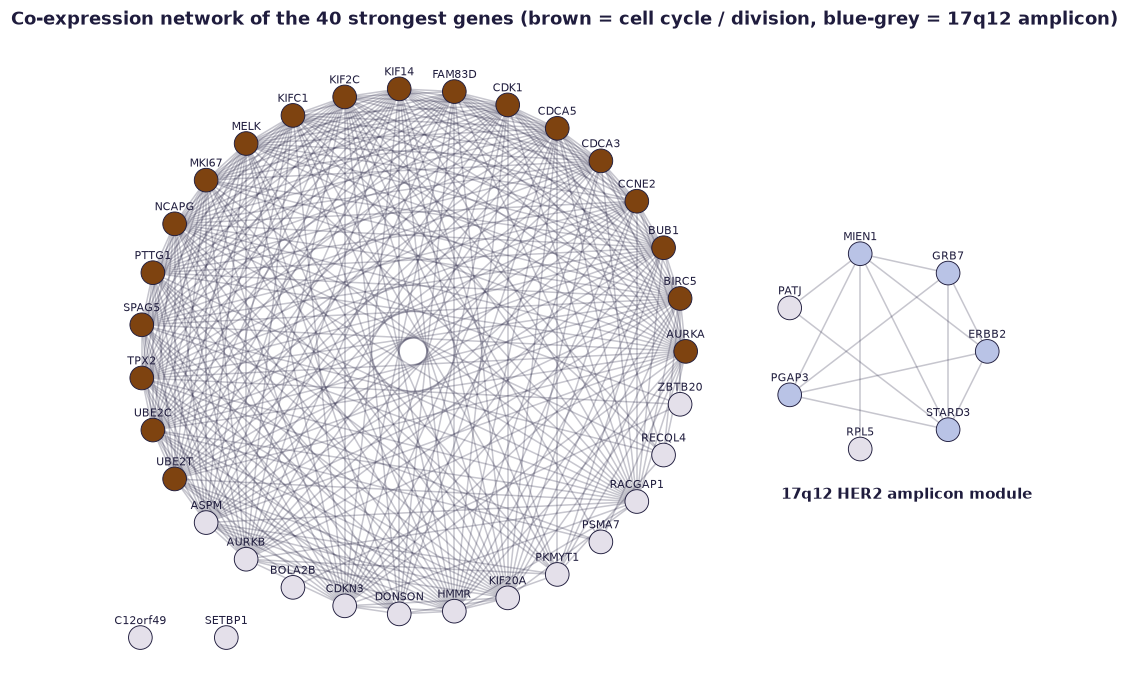

Largest connected module: 31 genes, 19 of them cell-cycle annotated; isolated genes: 2
The amplicon genes form their own module: ['ERBB2', 'GRB7', 'MIEN1', 'PATJ', 'PGAP3', 'RPL5', 'STARD3']
Caption: the strongest genes fall into two separate modules that rise and fall together: the proliferation programme, and the 17q12 amplicon.


In [32]:
# A small co-expression network of the 40 strongest genes (edge = |correlation| ≥ 0.75 across the 59 tumours)
import networkx as nx
net_probes = de[de.symbol != ""].drop_duplicates("symbol").head(40)
C = np.corrcoef(expr.loc[net_probes.index].values)
G = nx.Graph()
for pid, r in net_probes.iterrows():
    G.add_node(r.symbol.split("///")[0], cc=bool(r.cell_cycle), fc=float(r.log2FC))
names = [s.split("///")[0] for s in net_probes.symbol]
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        if abs(C[i, j]) >= 0.75:
            G.add_edge(names[i], names[j], r=float(C[i, j]))
# Lay out each module as its own ring so every label stays readable.
comps = sorted(nx.connected_components(G), key=len, reverse=True)
pos, x0 = {}, 0.0
for c in [c for c in comps if len(c) > 1]:
    rad = 0.35 + 0.045 * len(c)
    ring = nx.circular_layout(sorted(c, key=lambda n: (not G.nodes[n]["cc"], n)), scale=rad)
    pos.update({n: (x + x0 + rad, y) for n, (x, y) in ring.items()})
    x0 += 2 * rad + 0.6
singles = [n for c in comps if len(c) == 1 for n in c]
for i, n in enumerate(singles):
    pos[n] = (i * 0.55, -1.9)
fig, ax = plt.subplots(figsize=(12, 7.5))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25, edge_color=INK)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=240, node_color=[PROLIF if G.nodes[n]["cc"] else ("#B9C3E6" if n in AMPLICON else "#E4E0EA") for n in G], edgecolors=INK, linewidths=0.6)
nx.draw_networkx_labels(G, {n: (x, y + 0.11) for n, (x, y) in pos.items()}, ax=ax, font_size=7.5, font_color=INK)
amp_nodes = [n for n in G if n in AMPLICON]
if amp_nodes:
    cx, cy = np.mean([pos[n] for n in amp_nodes], axis=0)
    ax.text(cx, cy - 1.05, "17q12 HER2 amplicon module", ha="center", fontsize=9.5, fontweight="bold", color=INK)
ax.set_title("Co-expression network of the 40 strongest genes (brown = cell cycle / division, blue-grey = 17q12 amplicon)"); ax.axis("off")
save(fig, "06b_network")
big = comps[0]
print(f"Largest connected module: {len(big)} genes, {sum(G.nodes[n]['cc'] for n in big)} of them cell-cycle annotated; isolated genes: {sum(1 for c in comps if len(c) == 1)}")
amp_comp = [c for c in comps if set(AMPLICON) & c]
print(f"The amplicon genes form their own module: {sorted(amp_comp[0]) if amp_comp else 'none'}")
print("Caption: the strongest genes fall into two separate modules that rise and fall together: the proliferation programme, and the 17q12 amplicon.")

### What we found (Stage 6)
* **Genes higher in Luminal B are about cell division.** 122 GO processes pass FDR 5%, led by *cell division* (142 of its 318 genes, q ≈ 3×10⁻¹⁹), mitotic nuclear division, DNA replication and chromosome segregation. The Hallmark cross-check agrees: *G2-M checkpoint* (54/200) and *E2F targets* (51/200) top the list, and both are cell-division programmes.
* **Genes higher in Luminal A tell a different, weaker story.** The top processes are protein production (ribosome and translation genes) and extracellular-matrix organisation. The Hallmark sets are *estrogen response early/late* and EMT, all at modest q ≈ 0.02–0.03. This fits Luminal A being the more "classically hormone-driven" luminal tumour, and *PGR* (the progesterone receptor) is about 33× higher in Luminal A.
* **The proliferation share, our declared measurement:** **22 of the top 50** probes (44%) and **30 of the top 100** are cell-cycle genes, against 3.0% of the chip. 9 and 13 of them are our 21 PAM50 genes. Across *all* 8,269 significant probes the enrichment is real but modest (4.3% vs 3.0%, odds ratio 1.8, p = 2×10⁻¹⁵). Proliferation dominates the *top* of the list, not the whole list.
* **The proliferation score alone** ranks a Luminal B above a Luminal A 97% of the time (AUC 0.97), and one line on it agrees with 93% of labels. That figure is chosen with hindsight; Stage 7 gives honest numbers.
* **What survives adjusting for proliferation:** only **64 of 8,269** probes remain significant once the proliferation score is in the model. The strongest survivors are the five 17q12 amplicon genes.
* **The unplanned second line (exploratory):** the HER2-amplicon score separates the subtypes *even better* than proliferation (AUC 0.99 vs 0.97), and **25 of 30 Luminal B tumours have more *ERBB2* than any Luminal A tumour** (about 9× more on average). The two scores are correlated (r = 0.69), because HER2-amplified tumours also tend to divide fast, but they are not the same thing: both Luminal B tumours on the slow side of the proliferation line are HER2-high. In this cohort **"Luminal B" seems to mean "fast-dividing *or* HER2-amplified"**, which is the St Gallen definition. Because we chose these genes after looking, this is a hypothesis to test in another cohort, not a finding.
* **Two programmes, not many signals:** in the network the strongest genes form two separate modules, a large brown proliferation module and a small 17q12 amplicon module.
* **Interpretation, plainly:** our hypothesis is **half right**. Cell division is the biggest single theme, as predicted. But it is not the *only* dividing line: HER2 amplification is a second one.

---
# Stage 7 · Machine learning

**What we're doing.** We train a classifier (logistic regression, a simple and transparent model) to predict Luminal A vs B from expression. We then compare it with a **ladder of baselines** that keep or remove the cell-division genes.

**Why it matters.** This answers Objective 4 and puts a number on the honesty problem. With **59 tumours and ~28,600 features**, it is very easy to fool yourself. If you pick the "best" genes using all 59 tumours and only then cross-validate, the test tumours have already influenced the choice of genes. That is **data leakage**, and it inflates the score. So:
* We use **nested cross-validation**. The *outer* loop holds out a test fold to estimate performance. The *inner* loop, run only on the training tumours, chooses how many genes to keep and how strongly to regularise.
* Gene selection, scaling and tuning live **inside a scikit-learn `Pipeline`**, so they are refit on every training fold and never see the test fold.
* Folds are **stratified**, so both subtypes appear in every fold, and we **repeat** the outer split with different shuffles to measure the spread.

**The ladder (declared in Stage 1):**

| Rung | Features | What it tells us |
|---|---|---|
| Dummy (majority class) | none | The floor: is there any signal at all? |
| *MKI67* alone | 1 probe | Can the one gene pathologists stain for do the job? |
| Proliferation genes only | 21 PAM50 genes | How much comes from cell division alone? |
| Masked: no PAM50 genes | everything except the 21 | Is there anything beyond those 21 genes? |
| Masked: no cell-cycle genes | also drops GO cell cycle / division | …beyond the wider cell-cycle annotation? |
| Masked: no proliferation at all | also drops anything with \|r\| ≥ 0.4 to the proliferation score, recomputed in each training fold | …beyond the whole proliferation programme? |
| Full model | everything | The headline score |

*Added after Stage 6, so **exploratory** and not part of the declared plan:*

| Rung | Features | What it tells us |
|---|---|---|
| HER2 amplicon only | 5 genes on 17q12 | How much does the second line carry? |
| Both lines | 21 PAM50 + 5 amplicon genes | Do two simple scores explain the labels? |
| Masked: neither line | the strictest mask, plus the amplicon genes and anything with \|r\| ≥ 0.4 to the amplicon score | Is anything left beyond *both* lines? |

**What to look for below.** If the proliferation-only rung matches the full model, cell division explains the separation. That is the headline result. If the strictest masked rung falls towards 0.5, little separates the subtypes *beyond* proliferation. We report **ROC-AUC, accuracy and the error rate for each class**, as mean ± standard deviation across outer folds. Errors on Luminal B matter more, because calling a Luminal B tumour Luminal A could mean chemotherapy is not offered.

In [33]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = expr.T.values                         # 59 tumours × probes
y = is_b.astype(int)                      # 1 = Luminal B
probes = expr.index.to_numpy()
col = {p: i for i, p in enumerate(probes)}
pam50_cols = [col[p] for p in PROLIF_PROBES]                       # one probe per declared gene
pam50_all = np.where(in_pam50.reindex(expr.index).values)[0]      # every probe of those genes
cc_all = np.where(in_cc.values)[0]                                # GO cell cycle / division ∪ PAM50
mki_col = [col[MKI]]
her2_cols = [col[p] for p in AMP_PROBES]
amp_all = np.where(symbols_of.apply(lambda gs: any(g in AMPLICON for g in gs)).values)[0]
EXPLORATORY = {"her2", "both", "mask_both"}

class Columns(BaseEstimator, TransformerMixin):
    # Keep only the given columns (a fixed, label-free choice).
    def __init__(self, keep=None): self.keep = keep
    def fit(self, X, y=None): return self
    def transform(self, X): return X[:, self.keep]

class DropColumns(BaseEstimator, TransformerMixin):
    # Remove the given columns, and optionally anything correlated with the proliferation score.
    # The correlation is computed on the TRAINING fold only, inside fit().
    def __init__(self, drop=None, prolif_cols=None, r_max=None, extra_cols=None):
        self.drop, self.prolif_cols, self.r_max, self.extra_cols = drop, prolif_cols, r_max, extra_cols
    def fit(self, X, y=None):
        keep = np.ones(X.shape[1], bool); keep[self.drop] = False
        if self.r_max is not None:
            Z = (X - X.mean(0)) / (X.std(0) + 1e-9)
            for cols in [self.prolif_cols] + ([self.extra_cols] if self.extra_cols is not None else []):
                score = Z[:, cols].mean(1)
                r = (Z * ((score - score.mean()) / score.std())[:, None]).mean(0)
                keep &= np.abs(r) < self.r_max
        self.keep_ = np.where(keep)[0]
        return self
    def transform(self, X): return X[:, self.keep_]

LR = lambda: LogisticRegression(solver="liblinear", max_iter=2000)
K_GRID, C_GRID = [20, 100, 500], [0.05, 0.5]      # kept small so the notebook runs in minutes on Colab
def wide(drop_step):
    steps = ([("drop", drop_step)] if drop_step is not None else []) + [("k", SelectKBest(f_classif)), ("sc", StandardScaler()), ("clf", LR())]
    return Pipeline(steps), {"k__k": K_GRID, "clf__C": C_GRID}

MODELS = {
    "dummy":       ("Dummy (majority class)", "Dummy", Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]), None,
                    "Is there any signal at all?", "none: always predicts the larger class"),
    "mki67":       ("MKI67 alone", "MKI67 alone", Pipeline([("sel", Columns(mki_col)), ("sc", StandardScaler()), ("clf", LR())]), {"clf__C": C_GRID},
                    "Can the single gene pathologists stain for (Ki-67) do the job?", f"1 probe ({MKI})"),
    "prolif":      ("Proliferation genes only", "Proliferation only", Pipeline([("sel", Columns(pam50_cols)), ("sc", StandardScaler()), ("clf", LR())]), {"clf__C": C_GRID},
                    "How much of the separation comes from cell division alone?", "21 PAM50 proliferation genes"),
    "her2":        ("HER2 amplicon only (exploratory)", "HER2 amplicon only", Pipeline([("sel", Columns(her2_cols)), ("sc", StandardScaler()), ("clf", LR())]), {"clf__C": C_GRID},
                    "How much does the second dividing line, the 17q12 HER2 amplicon, carry on its own?", "5 amplicon genes on 17q12"),
    "both":        ("Both lines: proliferation + HER2 (exploratory)", "Both lines", Pipeline([("sel", Columns(pam50_cols + her2_cols)), ("sc", StandardScaler()), ("clf", LR())]), {"clf__C": C_GRID},
                    "Do two simple scores explain the labels?", "21 PAM50 + 5 amplicon genes"),
    "mask_pam50":  ("Masked: no PAM50 proliferation genes", "No PAM50 genes", *wide(DropColumns(drop=pam50_all)),
                    "Is there anything beyond those 21 genes?", f"all except {len(pam50_all)} PAM50 probes; best k chosen inside"),
    "mask_cc":     ("Masked: no cell-cycle genes", "No cell-cycle genes", *wide(DropColumns(drop=np.union1d(pam50_all, cc_all))),
                    "Is there anything beyond the annotated cell-cycle machinery?", f"all except {len(np.union1d(pam50_all, cc_all)):,} cell-cycle / PAM50 probes"),
    "mask_corr":   ("Masked: no proliferation signal at all", "No proliferation at all", *wide(DropColumns(drop=np.union1d(pam50_all, cc_all), prolif_cols=pam50_cols, r_max=0.4)),
                    "Is there anything beyond the whole proliferation programme?", "also drops |r| ≥ 0.4 with the proliferation score (per training fold)"),
    "mask_both":   ("Masked: neither proliferation nor HER2 (exploratory)", "Neither line", *wide(DropColumns(drop=np.union1d(np.union1d(pam50_all, cc_all), amp_all), prolif_cols=pam50_cols, r_max=0.4, extra_cols=her2_cols)),
                    "Is anything left beyond both dividing lines?", "also drops the amplicon and |r| ≥ 0.4 with either score (per training fold)"),
    "full":        ("Full model: all probes", "Full model", *wide(None),
                    "How well can expression separate the subtypes at all?", f"all {X.shape[1]:,} probes; best k chosen inside"),
}
print("Models defined:", ", ".join(m[1] for m in MODELS.values()))

Models defined: Dummy, MKI67 alone, Proliferation only, HER2 amplicon only, Both lines, No PAM50 genes, No cell-cycle genes, No proliferation at all, Neither line, Full model


In [34]:
N_REPEATS, N_FOLDS = 4, 5
outer = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=SEED)
inner = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
splits = list(outer.split(X, y))                 # identical splits for every model → paired comparison

def selected_probes(est):
    # Map the genes a fitted pipeline kept back to probe IDs.
    idx = np.arange(X.shape[1])
    if "drop" in est.named_steps: idx = idx[est.named_steps["drop"].keep_]
    if "k" in est.named_steps: idx = idx[est.named_steps["k"].get_support()]
    if "sel" in est.named_steps: idx = idx[est.named_steps["sel"].keep]
    return probes[idx]

results, oof, picked, t_start = {}, {}, {}, time.time()
for key, (label, short, pipe, grid, question, feats) in MODELS.items():
    folds, probs = [], np.full((N_REPEATS, len(y)), np.nan)
    counts = {}
    for f, (tr, te) in enumerate(splits):
        model = GridSearchCV(clone(pipe), grid, cv=inner, scoring="roc_auc", n_jobs=-1) if grid else clone(pipe)
        model.fit(X[tr], y[tr])
        best = model.best_estimator_ if grid else model
        pr = best.predict_proba(X[te])[:, 1]
        probs[f // N_FOLDS, te] = pr
        pred = (pr >= 0.5).astype(int)
        folds.append(dict(auc=roc_auc_score(y[te], pr), acc=(pred == y[te]).mean(),
                          errA=(pred[y[te] == 0] == 1).mean(), errB=(pred[y[te] == 1] == 0).mean()))
        if key != "dummy":
            for pid in selected_probes(best): counts[pid] = counts.get(pid, 0) + 1
    results[key], oof[key], picked[key] = pd.DataFrame(folds), probs, counts
    r = results[key]
    print(f"{short:24s} AUC {r.auc.mean():.3f} ± {r.auc.std():.3f} | accuracy {r.acc.mean():.1%} ± {r.acc.std():.1%} | "
          f"Lum A called B {r.errA.mean():.0%} | Lum B called A {r.errB.mean():.0%}")
print(f"\n{len(splits)} outer folds × {len(MODELS)} models in {time.time() - t_start:.0f} s")

Dummy                    AUC 0.500 ± 0.000 | accuracy 49.1% ± 1.9% | Lum A called B 80% | Lum B called A 20%


MKI67 alone              AUC 0.966 ± 0.051 | accuracy 89.0% ± 6.9% | Lum A called B 10% | Lum B called A 12%


Proliferation only       AUC 0.982 ± 0.040 | accuracy 94.9% ± 6.4% | Lum A called B 3% | Lum B called A 7%


HER2 amplicon only       AUC 0.984 ± 0.019 | accuracy 89.8% ± 8.8% | Lum A called B 0% | Lum B called A 20%


Both lines               AUC 0.996 ± 0.011 | accuracy 98.3% ± 3.5% | Lum A called B 0% | Lum B called A 3%


No PAM50 genes           AUC 0.991 ± 0.024 | accuracy 97.4% ± 5.0% | Lum A called B 1% | Lum B called A 4%


No cell-cycle genes      AUC 0.993 ± 0.016 | accuracy 96.2% ± 5.1% | Lum A called B 0% | Lum B called A 8%


No proliferation at all  AUC 0.969 ± 0.045 | accuracy 89.8% ± 7.7% | Lum A called B 5% | Lum B called A 15%


Neither line             AUC 0.957 ± 0.047 | accuracy 88.9% ± 5.8% | Lum A called B 8% | Lum B called A 14%


Full model               AUC 0.991 ± 0.030 | accuracy 97.4% ± 5.0% | Lum A called B 1% | Lum B called A 4%

20 outer folds × 10 models in 287 s


In [35]:
ladder = pd.DataFrame({MODELS[k][1]: {
    "ROC-AUC": f"{r.auc.mean():.3f} ± {r.auc.std():.3f}",
    "AUC 95% range": f"{np.percentile(r.auc, 2.5):.2f}–{np.percentile(r.auc, 97.5):.2f}",
    "accuracy": f"{r.acc.mean():.1%} ± {r.acc.std():.1%}",
    "Luminal A called B": f"{r.errA.mean():.1%}", "Luminal B called A": f"{r.errB.mean():.1%}"} for k, r in results.items()}).T
display(ladder)

def corrected_ttest(a, b, n_train, n_test):
    # Nadeau & Bengio (2003): fold scores share training data, so the naive t-test is too optimistic.
    d = np.asarray(a) - np.asarray(b); J = len(d)
    t = d.mean() / np.sqrt((1 / J + n_test / n_train) * d.var(ddof=1) + 1e-12)
    return d.mean(), 2 * stats.t.sf(abs(t), J - 1)

n_te = len(y) // N_FOLDS; n_tr = len(y) - n_te
COMPARE = {}
for a, b in [("full", "prolif"), ("prolif", "mki67"), ("full", "mask_corr"), ("full", "both"), ("full", "mask_both"), ("mask_both", "dummy")]:
    dm, pv = corrected_ttest(results[a].auc, results[b].auc, n_tr, n_te)
    COMPARE[(a, b)] = (dm, pv)
    print(f"{MODELS[a][1]:>24} − {MODELS[b][1]:<24} AUC difference {dm:+.3f}  (corrected p = {pv:.2f})")

,ROC-AUC,AUC 95% range,accuracy,Luminal A called B,Luminal B called A
Dummy,0.500 ± 0.000,0.50–0.50,49.1% ± 1.9%,80.0%,20.0%
MKI67 alone,0.966 ± 0.051,0.84–1.00,89.0% ± 6.9%,9.7%,12.5%
Proliferation only,0.982 ± 0.040,0.89–1.00,94.9% ± 6.4%,3.5%,6.7%
HER2 amplicon only,0.984 ± 0.019,0.94–1.00,89.8% ± 8.8%,0.0%,20.0%
Both lines,0.996 ± 0.011,0.97–1.00,98.3% ± 3.5%,0.0%,3.3%
No PAM50 genes,0.991 ± 0.024,0.93–1.00,97.4% ± 5.0%,1.0%,4.2%
No cell-cycle genes,0.993 ± 0.016,0.96–1.00,96.2% ± 5.1%,0.0%,7.5%
No proliferation at all,0.969 ± 0.045,0.86–1.00,89.8% ± 7.7%,5.2%,15.0%
Neither line,0.957 ± 0.047,0.87–1.00,88.9% ± 5.8%,8.0%,14.2%
Full model,0.991 ± 0.030,0.92–1.00,97.4% ± 5.0%,1.0%,4.2%


              Full model − Proliferation only       AUC difference +0.009  (corrected p = 0.33)
      Proliferation only − MKI67 alone              AUC difference +0.016  (corrected p = 0.30)
              Full model − No proliferation at all  AUC difference +0.022  (corrected p = 0.50)
              Full model − Both lines               AUC difference -0.005  (corrected p = 0.68)
              Full model − Neither line             AUC difference +0.034  (corrected p = 0.18)
            Neither line − Dummy                    AUC difference +0.457  (corrected p = 0.00)


**Leakage check: shuffle the labels.** If information were leaking from the test tumours into training, a pipeline could score well even on *meaningless* labels. So we shuffle the subtype labels at random and re-run the two most complex pipelines with exactly the same nested procedure. A leak-free pipeline should fall to about 0.5, a coin flip.

In [36]:
rng = np.random.default_rng(SEED)
PERM = {}
for key in ("full", "mask_both"):
    label, short, pipe, grid, *_ = MODELS[key]
    aucs = []
    for rep_i in range(2):
        yp = rng.permutation(y)
        for tr, te in StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=rep_i).split(X, yp):
            mdl = GridSearchCV(clone(pipe), grid, cv=inner, scoring="roc_auc", n_jobs=-1).fit(X[tr], yp[tr])
            aucs.append(roc_auc_score(yp[te], mdl.predict_proba(X[te])[:, 1]))
    PERM[key] = np.array(aucs)
    print(f"{short:14s} with SHUFFLED labels: AUC {PERM[key].mean():.2f} ± {PERM[key].std():.2f} over {len(aucs)} folds "
          f"(real labels: {results[key].auc.mean():.2f})")

Full model     with SHUFFLED labels: AUC 0.50 ± 0.25 over 10 folds (real labels: 0.99)


Neither line   with SHUFFLED labels: AUC 0.56 ± 0.21 over 10 folds (real labels: 0.96)


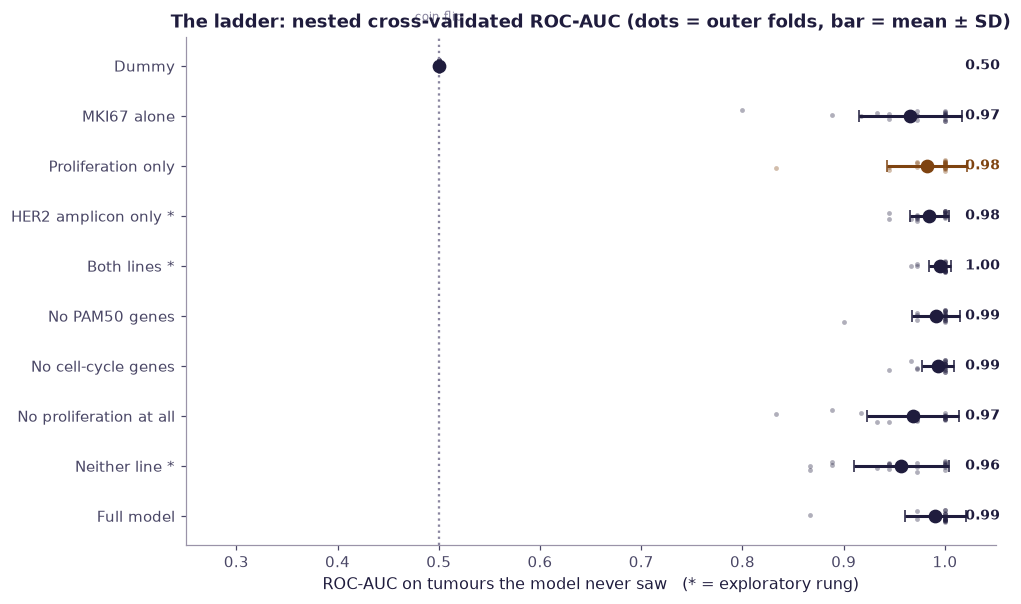

Caption: every rung that keeps the proliferation genes or the HER2 amplicon sits near the top; compare the bottom masked rung with the dummy.


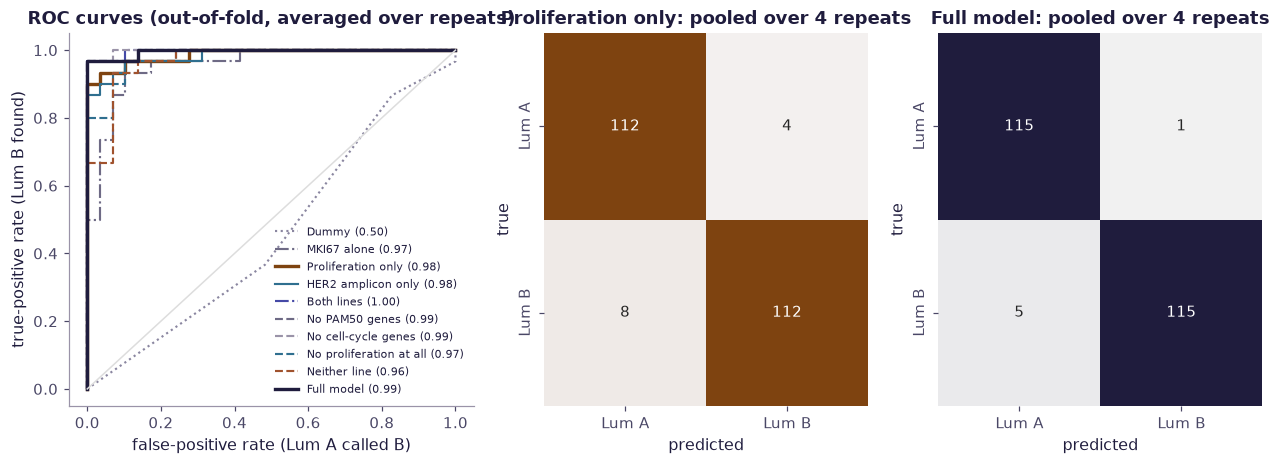

Caption: bottom-left cells count the costly error, Luminal B called Luminal A.


In [37]:
# Figures: the ladder, ROC curves, confusion matrices
keys = list(MODELS)
fig, ax = plt.subplots(figsize=(9.5, 6))
for i, k in enumerate(keys):
    r = results[k]; colr = PROLIF if k == "prolif" else INK
    ax.scatter(r.auc, np.full(len(r), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(r)), s=10, color=colr, alpha=0.35, lw=0)
    ax.errorbar(r.auc.mean(), i, xerr=r.auc.std(), fmt="o", color=colr, ms=8, capsize=4, lw=2)
    ax.text(1.02, i, f"{r.auc.mean():.2f}", va="center", fontsize=9, color=colr, fontweight="bold")
ax.axvline(0.5, color=MUTED, ls=":"); ax.text(0.5, -0.9, "coin flip", ha="center", fontsize=8, color=MUTED)
ax.set_yticks(range(len(keys)), [MODELS[k][1] + (" *" if k in EXPLORATORY else "") for k in keys]); ax.invert_yaxis()
ax.set(xlim=(0.25, 1.05), title="The ladder: nested cross-validated ROC-AUC (dots = outer folds, bar = mean ± SD)", xlabel="ROC-AUC on tumours the model never saw   (* = exploratory rung)")
save(fig, "07a_ladder")
print("Caption: every rung that keeps the proliferation genes or the HER2 amplicon sits near the top; compare the bottom masked rung with the dummy.")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
styles = {"dummy": (MUTED, ":"), "mki67": ("#6E6A85", "-."), "prolif": (PROLIF, "-"), "her2": ("#2F6F8F", "-"), "both": ("#4549A6", "-."),
          "mask_pam50": ("#6E6A85", "--"), "mask_cc": ("#9A93A8", "--"), "mask_corr": ("#2F6F8F", "--"), "mask_both": ("#A0522D", "--"), "full": (INK, "-")}
for k in keys:
    fpr, tpr, _ = roc_curve(y, np.nanmean(oof[k], axis=0))
    c, ls = styles[k]
    axes[0].plot(fpr, tpr, color=c, ls=ls, lw=2.2 if k in ("prolif", "full") else 1.4, label=f"{MODELS[k][1]} ({results[k].auc.mean():.2f})")
axes[0].plot([0, 1], [0, 1], color="#DDD", lw=1)
axes[0].set(title="ROC curves (out-of-fold, averaged over repeats)", xlabel="false-positive rate (Lum A called B)", ylabel="true-positive rate (Lum B found)")
axes[0].legend(fontsize=7.5, loc="lower right")
for ax, k in zip(axes[1:], ["prolif", "full"]):
    pred = (oof[k] >= 0.5).astype(int)
    cm = np.array([[((pred == a) & (y == t)).sum() for a in (0, 1)] for t in (0, 1)])
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap=sns.light_palette(PROLIF if k == "prolif" else INK, as_cmap=True), ax=ax,
                xticklabels=["Lum A", "Lum B"], yticklabels=["Lum A", "Lum B"])
    ax.set(title=f"{MODELS[k][1]}: pooled over {N_REPEATS} repeats", xlabel="predicted", ylabel="true")
save(fig, "07b_roc_confusion")
print("Caption: bottom-left cells count the costly error, Luminal B called Luminal A.")

In [38]:
full_top = sorted(picked["full"].items(), key=lambda kv: -kv[1])[:15]
print(f"Genes the full model picked most often across the {len(splits)} outer folds:")
for pid, c in full_top:
    print(f"  {symbol[pid] or pid:12s} {pid:14s} in {c}/{len(splits)} folds · cell-cycle: {'yes' if in_cc[pid] else 'no'}")
print(f"\nShare of those top-15 that are cell-cycle genes: {np.mean([in_cc[p] for p, _ in full_top]):.0%}; amplicon genes: {np.mean([any(g in AMPLICON for g in symbols_of[p]) for p, _ in full_top]):.0%}")
left = sorted(picked["mask_both"].items(), key=lambda kv: -kv[1])[:12]
print("\nWith both lines masked, the genes the model leans on most:")
print(", ".join(f"{symbol[p] or p} ({c}/{len(splits)})" for p, c in left))

Genes the full model picked most often across the 20 outer folds:
  SPAG5        203145_at      in 20/20 folds · cell-cycle: yes
  AURKA        204092_s_at    in 20/20 folds · cell-cycle: yes
  TPX2         210052_s_at    in 20/20 folds · cell-cycle: yes
  MIEN1        224447_s_at    in 20/20 folds · cell-cycle: no
  PGAP3        55616_at       in 20/20 folds · cell-cycle: no
  STARD3       202991_at      in 19/20 folds · cell-cycle: no
  ERBB2        216836_s_at    in 19/20 folds · cell-cycle: no
  PGAP3        221811_at      in 19/20 folds · cell-cycle: no
  AURKA        208079_s_at    in 18/20 folds · cell-cycle: yes
  GRB7         210761_s_at    in 18/20 folds · cell-cycle: no
  MKI67        212022_s_at    in 18/20 folds · cell-cycle: yes
  BOLA2B///BOLA2 209836_x_at    in 17/20 folds · cell-cycle: no
  UBE2C        202954_at      in 15/20 folds · cell-cycle: yes
  SETBP1       205933_at      in 15/20 folds · cell-cycle: no
  MKI67        212021_s_at    in 15/20 folds · cell-cycle:

### What we found (Stage 7)
*Every number here comes from nested cross-validation, so each tumour was scored only by models that never saw it during training. The ± values are standard deviations over the 20 outer test folds.*
* **The floor:** the dummy model scores AUC **0.50**. It always predicts whichever subtype is larger in its training folds, so it gets one class entirely wrong (on average 80% of Luminal A and 20% of Luminal B are misclassified). With a 29/30 split, accuracy alone (49%) would hide that.
* **One gene:** *MKI67* alone reaches AUC **0.97 ± 0.05** (89% accuracy). This is the molecular version of the Ki-67 stain pathologists use, and it already carries most of the signal.
* **The headline, as predicted:** the **21 proliferation genes reach AUC 0.98 ± 0.04, against 0.99 ± 0.03 for all 28,592 probes**. The difference (+0.01) is well within noise (corrected paired test p = 0.33). *Cell division carries almost all of the separating power.*
* **But not as predicted, the masks barely hurt.** Removing the 21 PAM50 genes (0.99) or every annotated cell-cycle gene (0.99) changes nothing, because hundreds of other genes carry the same signal. Removing the *whole* proliferation programme (every gene with |r| ≥ 0.4 to the proliferation score) still leaves **0.97 ± 0.05**. Our hypothesis expected this rung to collapse, and it did not.
* **Why (exploratory rungs):** the HER2 amplicon alone scores **0.98**, but it misses 20% of Luminal B tumours (the ones that are not HER2-amplified). **Both lines together reach 0.996 with only 3% of Luminal B missed**, at least as good as the full model. Two simple scores explain the labels. Yet even with **neither line** (proliferation and the amplicon both masked), AUC is still **0.96 ± 0.05**, far above the dummy.
* **That last number is real, not leakage:** with shuffled labels the same pipelines fall to about 0.5 (printed above). What the strictest model uses is a spread of individually weak genes (*CNOT7*, *AMN*, *ATRX*, *LIFR*…), no single strong one. There are three possible explanations, which we cannot separate here: genuine broad biology (Luminal A shows more oestrogen-response and *PGR* activity), leftover proliferation or HER2 signal in genes just below our |r| < 0.4 cut (a mask is never perfect), or the submitters' batch correction, which kept tumour type in its model (Nygaard *et al.*, 2016).
* **Errors by class:** the full model calls 1% of Luminal A "B" and 4% of Luminal B "A". The proliferation-only model gives 3% and 7%. The remaining mistakes lean towards the clinically costly direction, Luminal B called A.
* **Spread:** fold-to-fold standard deviations of 0.02–0.05 AUC look small. But with only ~12 tumours per test fold, one misranked pair moves a fold's score a lot. Read every number as a rough estimate from one small cohort.

---
# Stage 8 · Conclusions and limitations

### One conclusion per objective
1. **Compare expression (Objective 1).** Luminal A and Luminal B differ clearly. On the first principal component they mostly separate, with only 8 tumours in the overlap zone, and on the proliferation score the labels change along one continuous axis with no empty gap. The subtype boundary behaves like a cut-point drawn on a continuum.
2. **Significant genes (Objective 2).** **8,269 probes (5,631 genes) differ at a 5% false discovery rate**, against about 1,430 expected by chance at p < 0.05. They split evenly between the two directions. The strongest are higher in Luminal B, and Mann–Whitney U agrees for 95% of probes.
3. **What they do (Objective 3).** The strongest differences are dominated by **cell-division genes**: 22 of the top 50, with G2-M checkpoint and E2F targets at the top of the enrichment lists. Genes higher in Luminal A lean towards oestrogen response, protein production and *PGR*. Once proliferation is accounted for, only 64 probes still differ individually, led by an **unplanned second signal: the 17q12 HER2 (ERBB2) amplicon** (exploratory).
4. **Classification (Objective 4).** With leak-free nested cross-validation, **21 proliferation genes classify about as well as all 28,592 probes (AUC 0.98 vs 0.99)**. Removing proliferation does *not* break the classifier (0.97), partly because the HER2 amplicon separates the groups too (0.98 alone, exploratory), and even with both removed a weaker, diffuse signal remains (0.96). A label-shuffling check confirms this is not leakage.

### Answer to the research question
*The biggest single difference between Luminal A and Luminal B is how fast the tumour cells divide*, and a handful of cell-division genes reproduce the labels almost perfectly. In this cohort, however, the labels also encode **HER2 amplification**, and beyond both lines there is a diffuse residue of smaller differences.

**Verdict on the hypothesis: partly supported.** We predicted correctly that cell-division genes dominate and that a small proliferation set would match the full model. We predicted wrongly that the separation would *depend* on proliferation. It does not: a second built-in criterion (HER2) and many weak signals can stand in for it. We report that as a negative result for that half of the hypothesis.

### Limitations (specific, not generic)
* **59 samples against ~28,600 probes.** Every score is an estimate from one small cohort, with wide fold-to-fold spread. None of it is evidence for a clinical test.
* **The labels are built from what we measure.** Luminal B is defined by high proliferation, and clinically often by HER2 status too. We measured how well we can reproduce a definition, not an independent biological fact. GEO does not record which definition the submitters used. Our HER2 finding suggests it included HER2 status, but that inference is exploratory.
* **One French cohort, listed as Caucasian.** Breast cancer in African women tends to appear at a younger age and with a larger share of triple-negative disease. Kenyan series report that many patients are diagnosed before 50 and that 18–33% of tumours are triple-negative, depending on the setting. These findings **should not be assumed to transfer to Kenyan patients without local validation**.
* **The labels themselves carry noise.** Microarray subtyping disagrees with other methods (immunohistochemistry, other gene panels and platforms), most often by moving some Luminal A cases to Luminal B. The tumours in the overlap zone of our line-up are exactly the ones such methods would disagree on.
* **Processed intensities, not raw counts.** The GC-RMA normalisation and the batch correction are the submitters', not ours. Their batch model included tumour type as a factor, which can overstate group differences (Nygaard *et al.*, 2016). Our check showed the subtypes are spread fairly evenly across batches, which limits that risk without removing it.
* **Gene annotation is incomplete.** The GO cell-cycle set uses direct annotations only and the annotation file dates from 2016, so our "beyond proliferation" masks may leave some proliferation genes in.

> **Research use only.** This is a coursework analysis. It must **not** inform any clinical decision. A Luminal B tumour misclassified as Luminal A could lead a clinician to withhold chemotherapy that a patient needed.

### Concrete next steps
1. **Test the two-line idea properly:** in a new cohort with recorded HER2 and Ki-67 status, check whether "fast *or* HER2-positive" predicts the Luminal B label, as it seems to here.
2. **Validate on an independent cohort,** for example TCGA-BRCA (RNA-seq) or METABRIC, to see whether the proliferation-only result holds on a different platform.
3. **Test on African cohorts,** for example Kenyan or other East African breast-cancer expression data where available, given the different subtype mix and age profile.
4. **Use an independent label,** such as Ki-67 immunohistochemistry scored by a pathologist, or patient outcome (relapse-free survival), instead of expression-derived labels. That would break the circularity.
5. **Treat proliferation as continuous.** Model it as a score with uncertainty rather than forcing a binary cut, and report which tumours sit in the grey zone.
6. **Re-run with raw CEL files** and our own normalisation, so the whole pipeline is ours, including batch handling.

### Key numbers, printed from the results (so the text above can be checked)

In [39]:
r = {k: v.auc.mean() for k, v in results.items()}
print(f"Tumours: {len(meta)} ({(~is_b).sum()} Luminal A, {is_b.sum()} Luminal B) · probes analysed: {len(de):,}")
print(f"FDR < 5%: {(de.q < 0.05).sum():,} probes (expected false positives at raw p < 0.05: {0.05 * len(de):,.0f})")
print(f"Top 50 probes: {share[50]['cell_cycle']} cell-cycle, {share[50]['pam50']} PAM50 · top 100: {share[100]['cell_cycle']} cell-cycle, {share[100]['pam50']} PAM50")
print(f"Probes still significant after adjusting for proliferation: {len(surv):,}")
print("AUC  " + " · ".join(f"{MODELS[k][1]} {v:.2f}" for k, v in r.items()))
print(f"Full − proliferation-only AUC: {COMPARE[('full', 'prolif')][0]:+.3f} (corrected p = {COMPARE[('full', 'prolif')][1]:.2f})")
print(f"HER2-amplicon score AUC {auc_her2:.2f}; {above}/30 Luminal B above the highest Luminal A ERBB2 · shuffled-label AUC: "
      + ", ".join(f"{MODELS[k][1]} {v.mean():.2f}" for k, v in PERM.items()))
print(f"Total runtime: {time.time() - T0:.0f} s")

Tumours: 59 (29 Luminal A, 30 Luminal B) · probes analysed: 28,592
FDR < 5%: 8,269 probes (expected false positives at raw p < 0.05: 1,430)
Top 50 probes: 22 cell-cycle, 9 PAM50 · top 100: 30 cell-cycle, 13 PAM50
Probes still significant after adjusting for proliferation: 64
AUC  Dummy 0.50 · MKI67 alone 0.97 · Proliferation only 0.98 · HER2 amplicon only 0.98 · Both lines 1.00 · No PAM50 genes 0.99 · No cell-cycle genes 0.99 · No proliferation at all 0.97 · Neither line 0.96 · Full model 0.99
Full − proliferation-only AUC: +0.009 (corrected p = 0.33)
HER2-amplicon score AUC 0.99; 25/30 Luminal B above the highest Luminal A ERBB2 · shuffled-label AUC: Full model 0.50, Neither line 0.56
Total runtime: 462 s


---
### Appendix · export for the companion site
This cell writes the numbers behind the interactive companion site as JSON files. When the notebook runs inside a clone of the repository they go to `web/public/data/`; anywhere else (Colab) they go to `site_data/`. Nothing in the analysis depends on this cell.

In [40]:
OUT = Path("web/public/data") if Path("web").exists() else Path("site_data")
OUT.mkdir(parents=True, exist_ok=True)
rd = lambda v, d=3: float(round(float(v), d))
sid = meta.index.tolist()
stat = lambda s: dict(mean=rd(s.mean()), sd=rd(s.std()), lo=rd(np.percentile(s, 2.5)), hi=rd(np.percentile(s, 97.5)))

samples = []
for i, s in enumerate(sid):
    v = expr[s].values
    samples.append(dict(id=s, title=meta.at[s, "title"], subtype="LumB" if is_b[i] else "LumA", batch=meta.at[s, "batch"],
        prolif=rd(meta.at[s, "prolif"]), her2=rd(meta.at[s, "her2"]), erbb2=rd(meta.at[s, "ERBB2"]), mki67=rd(meta.at[s, "MKI67"]), pc1=rd(meta.at[s, "PC1"]), pc2=rd(meta.at[s, "PC2"]),
        q1=rd(np.percentile(v, 25)), median=rd(np.median(v)), q3=rd(np.percentile(v, 75)),
        whiskLo=rd(np.percentile(v, 2.5)), whiskHi=rd(np.percentile(v, 97.5)), meanCorr=rd(meta.at[s, "mean_corr"], 4),
        flagged=bool(meta.at[s, "flagged"]), oof={k: rd(np.nanmean(oof[k][:, i])) for k in MODELS}))

genes_out = []
uniq = de[de.symbol != ""].drop_duplicates("symbol").head(300)
for rank, (pid, g) in enumerate(uniq.iterrows(), 1):
    genes_out.append(dict(probe=pid, symbol=g.symbol.split("///")[0], title=g["title"].split("///")[0], chrom=g["chrom"].split("///")[0],
        log2fc=rd(g.log2FC), p=float(f"{g.p:.3e}"), q=float(f"{g.q:.3e}"), mwQ=float(f"{g.q_mw:.3e}"), meanA=rd(g.mean_A), meanB=rd(g.mean_B),
        pam50=bool(g.pam50), cellCycle=bool(g.cell_cycle), amplicon=any(x in AMPLICON for x in g.symbol.split("///")), rank=rank, values=[rd(x, 2) for x in expr.loc[pid, sid].values]))

vol = de.copy()
lab = vol[vol.symbol != ""].drop_duplicates("symbol").head(40)
pos_of = {p: i for i, p in enumerate(vol.index)}
volcano = dict(x=[rd(v) for v in vol.log2FC], y=[rd(v) for v in -np.log10(vol.p)], sig=[int(v) for v in vol.q < 0.05],
               pam50=[int(v) for v in vol.pam50], cc=[int(v) for v in vol.cell_cycle], sym=[s.split("///")[0] for s in vol.symbol],
               probe=vol.index.tolist(), labels=[dict(i=pos_of[p], symbol=r.symbol.split("///")[0], probe=p) for p, r in lab.iterrows()], qLine=rd(q_line))

models_out = []
for k, (label, short, pipe, grid, question, feats) in MODELS.items():
    res = results[k]; mp = np.nanmean(oof[k], axis=0)
    fpr, tpr, _ = roc_curve(y, mp)
    pred = (oof[k] >= 0.5).astype(int); yy = np.tile(y, (N_REPEATS, 1))
    top = sorted(picked.get(k, {}).items(), key=lambda kv: -kv[1])[:20]
    models_out.append(dict(key=k, label=label, short=short, question=question, features=feats, exploratory=k in EXPLORATORY,
        folds=[{m: rd(row[m]) for m in ("auc", "acc", "errA", "errB")} for _, row in res.iterrows()],
        auc=stat(res.auc), acc=stat(res.acc), errA=stat(res.errA), errB=stat(res.errB),
        roc=dict(fpr=[rd(v) for v in fpr], tpr=[rd(v) for v in tpr]),
        confusion=dict(aa=int(((yy == 0) & (pred == 0)).sum()), ab=int(((yy == 0) & (pred == 1)).sum()),
                       ba=int(((yy == 1) & (pred == 0)).sum()), bb=int(((yy == 1) & (pred == 1)).sum())),
        topFeatures=[dict(symbol=symbol[p].split("///")[0], probe=p, freq=rd(c / len(splits))) for p, c in top] if k != "dummy" else []))

a_full, a_prolif, a_corr, a_her2, a_both, a_none = (r[k] for k in ("full", "prolif", "mask_corr", "her2", "both", "mask_both"))
d_fp, p_fp = COMPARE[("full", "prolif")]
perm_txt = ", ".join(f"{v.mean():.2f}" for v in PERM.values())
verdict = (f"Proliferation genes alone reach AUC {a_prolif:.2f} against {a_full:.2f} for every probe (difference {d_fp:+.2f}, corrected p = {p_fp:.2f}). "
           f"Masking the whole proliferation programme still leaves {a_corr:.2f}, partly because the 17q12 HER2 amplicon separates the subtypes on its own "
           f"(AUC {a_her2:.2f}, exploratory). With both lines masked the score is still {a_none:.2f}; with shuffled labels it falls to {perm_txt}, so this is not leakage.")
cc50 = share[50]["cell_cycle"]
headline = (f"Mostly cell division, but not only. Cell-division genes are the biggest theme ({cc50} of the 50 strongest differences), and 21 of them "
            f"classify the subtypes almost as well as all {len(de):,} probes (AUC {a_prolif:.2f} vs {a_full:.2f}). A second line, the HER2 amplicon "
            f"on chromosome 17, separates them just as well, and even with both removed the score is {a_none:.2f}.")

def hall(name):
    if name not in hallmark:
        return []
    h = hallmark[name]; h = h[h["Adjusted P-value"] < 0.05].head(5)
    return [dict(term=row["Term"], source="MSigDB Hallmark", q=float(f"{row['Adjusted P-value']:.3e}"), overlap=row["Overlap"],
                 genes=str(row["Genes"]).split(";")[:12]) for _, row in h.iterrows()]

def terms(res, src):
    out = res[res.q < 0.05].head(10)
    return [dict(term=t.term, source=src, q=float(f"{t.q:.3e}"), overlap=f"{t.k}/{t.K}", genes=t.genes[:12]) for t in out.itertuples()]

site = dict(
    summary=dict(generated=time.strftime("%Y-%m-%d"),
        dataset=dict(accession="GSE45827", platform="GPL570", platformTitle="Affymetrix Human Genome U133 Plus 2.0",
            institute="Institut Curie", country="France", title=series_meta["title"][0], pmid=series_meta.get("pubmed_id", [""])[0],
            citation="Gruosso et al., EMBO Molecular Medicine 2016", url="https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE45827",
            matrixUrl=MATRIX_URL, processing=PROCESSING, seriesSamples=int(expr_all.shape[1]), seriesProbes=int(expr_all.shape[0])),
        counts=dict(lumA=int((~is_b).sum()), lumB=int(is_b.sum()), probesInMatrix=int(n0), probesAfterMissing=int(n_missing),
            probesAfterVariance=int(n_var), varianceCutoff=SD_CUTOFF, flagged=FLAGGED),
        logDecision={k: (rd(v) if isinstance(v, float) else v) for k, v in LOG_DECISION.items()},
        annotation=dict(matchRate=rd(match_rate, 4), source="the GEO GPL570 annotation file (GPL570.annot.gz)"),
        de=dict(tested=int(n_tests), fdr05=int((de.q < 0.05).sum()), fdr05UpInB=int(((de.q < 0.05) & (de.log2FC > 0)).sum()),
            fdr05UpInA=int(((de.q < 0.05) & (de.log2FC < 0)).sum()),
            genesFdr05=int(de.loc[de.q < 0.05, "symbol"].str.split("///").explode().replace("", np.nan).dropna().nunique()),
            expectedFalseAtP05=int(round(0.05 * n_tests)), rawP05=int((de.p < 0.05).sum()), mannWhitneyAgree=rd(agree, 4)),
        prolif=dict(set=PAM50_PROLIF, probesFound=int(de.pam50.sum()), genesFound=found, top50=dict(pam50=share[50]["pam50"], cellCycle=share[50]["cell_cycle"]),
            top100=dict(pam50=share[100]["pam50"], cellCycle=share[100]["cell_cycle"]), cellCycleShareSig=rd(cc_sig, 4), cellCycleShareBackground=rd(cc_bg, 4),
            enrichmentOR=rd(odds, 2), enrichmentP=float(f"{p_enrich:.3e}"), scoreAuc=rd(auc_score), mki67Probe=MKI,
            mki67P=float(f"{mki_table.loc[MKI, 'Welch p']:.3e}"), mki67Fc=rd(diff)),
        bestCut=dict(threshold=rd(best_cut), accuracy=rd(max(acc_at)),
            errA=rd(((meta.prolif >= best_cut) & ~is_b).sum() / (~is_b).sum()), errB=rd(((meta.prolif < best_cut) & is_b).sum() / is_b.sum())),
        pca=dict(var1=rd(ve[0], 4), var2=rd(ve[1], 4), nProbes=5000, overlap=int(len(in_overlap))),
        her2=dict(genes=AMPLICON, probes=AMP_PROBES, band="17q12", scoreAuc=rd(auc_her2), bestCut=rd(her2_cut), accuracy=rd(max(acc_h)),
            lumBAboveMaxA=above, corrWithProlif=rd(r_ph), slowLumB=int(len(slow_b)), slowLumBHer2High=rescued, orRuleAccuracy=rd(or_rule.mean()),
            erbb2Probe=amp_tab.at["ERBB2", "probe"], erbb2Fc=rd(amp_tab.at["ERBB2", "mean_B"] - amp_tab.at["ERBB2", "mean_A"])),
        adjusted=dict(survivors=int(len(surv)), upInB=int((surv.subtype_effect > 0).sum()), upInA=int((surv.subtype_effect < 0).sum()),
            top=[dict(symbol=(r_.symbol or pid).split("///")[0], probe=pid, effect=rd(r_.subtype_effect), q=float(f"{r_.q:.3e}")) for pid, r_ in surv.head(20).iterrows()]),
        headline=headline),
    samples=samples,
    classifier=dict(outer=f"{N_FOLDS}-fold stratified, repeated {N_REPEATS}×", inner="5-fold stratified grid search",
        repeats=N_REPEATS, folds=N_FOLDS, grid=f"k ∈ {K_GRID}, C ∈ {C_GRID}", models=models_out, verdict=verdict,
        permutation={k: dict(mean=rd(v.mean()), sd=rd(v.std()), n=int(len(v))) for k, v in PERM.items()}),
    enrichment=dict(method=(f"One-sided hypergeometric test of every Gene Ontology biological process (10–500 genes) in the GPL570 annotation, "
                            f"run separately for the {len(up_b_genes):,} genes higher in Luminal B and the {len(up_a_genes):,} higher in Luminal A at FDR 5%, "
                            f"with Benjamini–Hochberg correction across processes."),
        upInB=hall("upInB") + terms(enr_b, "GO BP"), upInA=hall("upInA") + terms(enr_a, "GO BP"),
        network=dict(nodes=[dict(id=n, pam50=n in PAM50_PROLIF, cellCycle=G.nodes[n]["cc"], fc=rd(G.nodes[n]["fc"])) for n in G],
                     edges=[dict(s=u, t=v, r=rd(d["r"])) for u, v, d in G.edges(data=True)])),
)
(OUT / "site.json").write_text(json.dumps(site, ensure_ascii=False), encoding="utf-8")
(OUT / "genes.json").write_text(json.dumps(genes_out, ensure_ascii=False), encoding="utf-8")
(OUT / "volcano.json").write_text(json.dumps(volcano, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
print("Wrote", ", ".join(f"{p.name} ({p.stat().st_size/1e3:.0f} kB)" for p in sorted(OUT.glob("*.json"))), "to", OUT)
print(headline)

Wrote genes.json (194 kB), site.json (85 kB), volcano.json (1122 kB) to web\public\data
Mostly cell division, but not only. Cell-division genes are the biggest theme (22 of the 50 strongest differences), and 21 of them classify the subtypes almost as well as all 28,592 probes (AUC 0.98 vs 0.99). A second line, the HER2 amplicon on chromosome 17, separates them just as well, and even with both removed the score is 0.96.
